# ☕ Proyecto **Centinela** · Fase 2 — *Centinela del Café*: del MLP al sistema multimodal
Maestría en Ciencia de Datos · Universidad Santo Tomás

**Autor:** Julio César González R. · **Modalidad:** individual · **Entrega:** 2026-11-16

**Pregunta del cliente (la misma de la Fase 1).** ¿Puede el sistema avisar, a partir de la foto de una hoja de café robusta, si está enferma, y de qué, para que el técnico de campo priorice la inspección?

**Para esta actividad fase 2** La rama A reemplaza el pasado resumen por una **red convolucional preentrenada** que mira la foto completa y aprende sus propios filtros. El objetivo pasa de 2 a **3 clases** (la actividad pide al menos 3): **sana · ácaro · roya**.

| Sección | Qué se hace | Criterio |
|---|---|---|
| A0 | Entorno, GPU, semillas, rutas en Drive | 1 |
| A1 | Descarga trazable (huella SHA-256) y etiquetas de 3 clases | 1 |
| A2 | Caché de imágenes a 224 × 384 | 1 |
| A3 | EDA de imágenes: clases, tamaños, iluminación, fondo | 1 |
| A3b | Auditoría de duplicados: misma foto bajo dos plantas, etiquetas contradictorias | 1, 5 |
| A4 | Partición 70/15/15 , estratificada | 1 |
| A5 | Comparación ResNet50 vs EfficientNet-B0: parámetros, profundidad, velocidad | 1 |
| A6 | *Feature Extraction* (red congelada) en las dos arquitecturas | 1 |
| A7 | *Fine-Tuning* del último bloque, con aumento de datos y puntos de control | 1 |
| A8 | Elección del modelo | 1 |
| A9 | Evaluación única en prueba, comparación con la Fase 1 y errores por severidad | 1, 5 |
| A10 | Grad-CAM: ¿mira la hoja o el fondo? (cualitativo y cuantitativo) | 1 |
| A11 | Pesos `.pth` y *embeddings* para la fusión (rama C) | 1, 3 |
| B1–B7 | Rama B: clima diario NASA POWER 2001–2024, ventanas de 14 días, RNN de contraste, LSTM y GRU, desvanecimiento del gradiente | 2 |
| C0–C4 | Rama C: clave real (Calceta, fecha EXIF), fusión con ablación, fusión para la decisión semanal del técnico, boletín | 3, 5 |


## A0 · Preparación del entorno

In [2]:
# Celda A0: Entorno, semillas, dispositivo y rutas
# Importa librerías, fija semillas, detecta la GPU y monta Google Drive.

import os, io, re, json, copy, time, random, shutil, hashlib, tarfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
from torchvision.transforms import v2 as T
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, classification_report, precision_recall_fscore_support,
                             f1_score, accuracy_score, roc_auc_score, average_precision_score)

SEMILLA = 42
def fijar_semillas(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
fijar_semillas()
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODO_PRUEBA = os.environ.get("CENTINELA_PRUEBA") == "1"
PESOS_IMAGENET = os.environ.get("CENTINELA_SIN_PESOS") != "1"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = "/content/drive/MyDrive"
    TEMP = "/content/tmp_centinela"
except ImportError:
    RAIZ = os.environ.get("CENTINELA_RAIZ", "centinela")
    TEMP = os.path.join(RAIZ, "tmp")
BASE = os.path.join(RAIZ, "centinela_fase2")
DATOS = os.path.join(BASE, "datos"); CKPT = os.path.join(BASE, "checkpoints"); PESOS = os.path.join(BASE, "pesos")
DATOS_F1 = os.path.join(RAIZ, "centinela_fase1", "datos")    # se reutiliza lo descargado en la Fase 1
for d in (DATOS, CKPT, PESOS, TEMP): os.makedirs(d, exist_ok=True)

COLORES = {"sana": "#1b6e3a", "acaro": "#7b3fa0", "roya": "#b5532a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"torch {torch.__version__} · torchvision {torchvision.__version__} · dispositivo: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
if DEVICE.type != "cuda":
    print("⚠️ Sin GPU: el ajuste fino será muy lento. En Colab: Entorno de ejecución → Cambiar tipo → GPU.")

Mounted at /content/drive
torch 2.14.1+cu130 · torchvision 0.29.1+cu130 · dispositivo: cuda (Tesla T4)


## A1 · Descarga trazable y etiquetas de 3 clases

Las mismas fuentes de la Propuesta de Datos aprobada, descargadas del productor primario (Mendeley Data) con su huella SHA-256 verificada. Si la Fase 1 ya las dejó en Drive, se reutilizan.

**De 6 clases a 3.** La actividad pide al menos 3 categorías. Se conserva la información útil para el técnico: **sana**, **ácaro** (otro agente, otro tratamiento) y **roya** (los niveles 1 a 4 juntos). El nivel de roya se guarda aparte para analizar los errores por severidad, igual que en la Fase 1.

| Clase original | Clase de la Fase 2 |
|---|---|
| healthy | sana |
| red_spider_mite | ácaro |
| rust_level_1 … rust_level_4 | roya |

In [3]:
# Celda A1 Descarga con huella SHA-256 y construcción de etiquetas
# Descarga (o reutiliza) el CSV de anotaciones y el paquete de fotos; verifica la huella; arma la tabla.

MENDELEY_API = "https://data.mendeley.com/public-api/datasets/c5yvn32dzg"
CABECERAS = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0 Safari/537.36"}
ARCHIVOS = {   # huellas publicadas por Mendeley (registradas en el anexo B de la Propuesta)
    "RoCoLE-csv.csv": {"destino": DATOS, "sha256": "a9aa6b411569dba7e9ba56fed79e5cd82af04a0ef092e56309158d632ac5205b",
        "url": "https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/e39cecdd-8dca-445a-b734-10229427f2fa/file_downloaded"},
    "RoCoLe-voc.tar.gz": {"destino": TEMP, "sha256": "7b45c70c5a1e4270ff456ab95d07dca2c6533d15954015ba0261cdcdc016b485",
        "url": "https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/3cfa348c-179b-4f05-9a6d-6c9343dd5c03/file_downloaded"}}
VERIFICAR_HUELLA = not MODO_PRUEBA

def sha256_archivo(ruta, bloque=2**22):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""): h.update(trozo)
    return h.hexdigest()

def descargar(url, ruta):
    parcial = ruta + ".parcial"
    with urllib.request.urlopen(urllib.request.Request(url, headers=CABECERAS), timeout=900) as r, open(parcial, "wb") as f:
        shutil.copyfileobj(r, f, 2**22)
    os.replace(parcial, ruta)

def obtener(nombre, necesario=True):
    meta = ARCHIVOS[nombre]; ruta = os.path.join(meta["destino"], nombre)
    previo = os.path.join(DATOS_F1, nombre)
    if not os.path.exists(ruta) and os.path.exists(previo):
        shutil.copy(previo, ruta); print(f"{nombre}: copiado desde la carpeta de la Fase 1")
    if not os.path.exists(ruta):
        if not necesario: return None
        print(f"Descargando {nombre}…"); descargar(meta["url"], ruta)
    if VERIFICAR_HUELLA and sha256_archivo(ruta) != meta["sha256"]:
        raise ValueError(f"La huella de {nombre} no coincide con la publicada por Mendeley")
    return ruta

RUTA_CSV = obtener("RoCoLE-csv.csv")
crudo = pd.read_csv(RUTA_CSV)
etiquetas = crudo[["ID", "External ID", "Label"]].rename(columns={"ID": "id", "External ID": "archivo", "Label": "label_json"})
del crudo                                                       # «Created By» (correo del anotador) nunca se usa
lab = etiquetas.pop("label_json").apply(json.loads)
etiquetas["nivel"] = lab.apply(lambda d: d["classification"])
etiquetas["poligonos"] = lab.apply(lambda d: [[(p["x"], p["y"]) for p in h["geometry"]] for h in d.get("Leaf", [])])
CLASES = ["sana", "acaro", "roya"]
A_CLASE = {"healthy": "sana", "red_spider_mite": "acaro"}
etiquetas["clase"] = etiquetas["nivel"].map(lambda n: A_CLASE.get(n, "roya"))
etiquetas["y"] = etiquetas["clase"].map(CLASES.index)
m = etiquetas["archivo"].str.extract(r"^C(\d+)P(\d+)")
etiquetas["seccion"] = "C" + m[0]; etiquetas["planta"] = "C" + m[0] + "P" + m[1]
print(f"{len(etiquetas)} fotos · {etiquetas.planta.nunique()} plantas")
print(etiquetas["clase"].value_counts().reindex(CLASES).to_string())

1560 fotos · 390 plantas
clase
sana     791
acaro    167
roya     602


## A2 · Caché de imágenes a 224 × 384

Las fotos llegan en tres tamaños (1280 × 720, 2048 × 1152 y 4128 × 2322), todas horizontales (16:9). Se reducen **una sola vez** a **224 × 384** píxeles —224 es el lado con que se preentrenaron las redes de ImageNet; 384 conserva casi la proporción original sin recortar la hoja— y se guardan en Drive como un arreglo `uint8` (≈ 400 MB). Así cada entrenamiento lee la caché en segundos en vez de decodificar 700 MB de JPEG.

No se recorta la hoja con su contorno: en el uso real el técnico no tendrá ese contorno, solo la foto. El contorno se usa más adelante **solo para medir** si el Grad-CAM mira la hoja (A10).

In [4]:
# Celda A2 · Caché de imágenes reducidas (se ejecuta una vez y se guarda en Drive)
# Lee cada foto del paquete VOC, la reduce a 224×384 RGB y guarda el arreglo y los tamaños originales.

ALTO, ANCHO = 224, 384
RUTA_CACHE = os.path.join(DATOS, f"imagenes_{ALTO}x{ANCHO}.npy")
RUTA_META = os.path.join(DATOS, f"imagenes_{ALTO}x{ANCHO}_meta.csv")

if os.path.exists(RUTA_CACHE) and os.path.exists(RUTA_META):
    meta_img = pd.read_csv(RUTA_META)
    IMGS = np.load(RUTA_CACHE)
    print(f"Caché reutilizada: {IMGS.shape}")
else:
    RUTA_TAR = obtener("RoCoLe-voc.tar.gz")
    ids_validos = set(etiquetas.id)
    filas, arreglos, t0 = [], [], time.time()
    with tarfile.open(RUTA_TAR, "r:gz") as tar:
        for miembro in tar:
            nombre = os.path.basename(miembro.name)
            if not nombre.lower().endswith((".jpeg", ".jpg")): continue
            id_img = os.path.splitext(nombre)[0]
            if id_img not in ids_validos: continue
            img = Image.open(io.BytesIO(tar.extractfile(miembro).read()))
            w0, h0 = img.size
            img.draft("RGB", (ANCHO * 2, ALTO * 2))           # decodificación rápida a escala reducida
            img = img.convert("RGB").resize((ANCHO, ALTO), Image.BILINEAR)
            arreglos.append(np.asarray(img, dtype=np.uint8)); filas.append({"id": id_img, "ancho0": w0, "alto0": h0})
            if len(filas) % 300 == 0: print(f"  {len(filas)} imágenes ({time.time()-t0:.0f} s)")
    meta_img = pd.DataFrame(filas); IMGS = np.stack(arreglos)
    np.save(RUTA_CACHE, IMGS); meta_img.to_csv(RUTA_META, index=False)
    print(f"Caché creada: {IMGS.shape} en {time.time()-t0:.0f} s → {RUTA_CACHE}")

tabla = meta_img.reset_index().rename(columns={"index": "fila"}).merge(etiquetas, on="id", how="inner")
if MODO_PRUEBA:                                      # verificación rápida del código con pocas fotos
    tabla = pd.concat([tabla[tabla.clase == c].head(60) for c in CLASES]).reset_index(drop=True)
else:
    assert len(tabla) == len(etiquetas), "Faltan imágenes en la caché"
print(f"Tabla de trabajo: {len(tabla)} fotos con imagen y etiqueta")

Caché reutilizada: (1560, 224, 384, 3)
Tabla de trabajo: 1560 fotos con imagen y etiqueta


## A3 · Exploración de las imágenes (EDA)

Cinco preguntas, cada una con su decisión: (a) balance de clases; (b) tamaños de origen; (c) cómo se ve cada clase; (d) variación de iluminación; (e) cuánto de la foto es hoja y cuánto fondo.

(a) Balance de clases:
       fotos   pct
clase             
sana     791  50.7
acaro    167  10.7
roya     602  38.6

    Niveles dentro de «roya»: {'rust_level_1': 344, 'rust_level_2': 166, 'rust_level_3': 62, 'rust_level_4': 30}

(b) Resoluciones de origen:
clase       sana  acaro  roya
resolucion                   
1280×720     249     27   203
2048×1152    387     70   311
4128×2322    155     70    88

(d) Brillo medio (0–1) y (e) fracción de la foto ocupada por la hoja, por clase:
      brillo                      frac_hoja                     
        mean    std    min    max      mean    std    min    max
clase                                                           
sana   0.404  0.052  0.235  0.574     0.245  0.089  0.061  0.582
acaro  0.401  0.061  0.238  0.554     0.246  0.104  0.078  0.541
roya   0.411  0.056  0.236  0.571     0.283  0.092  0.084  0.555


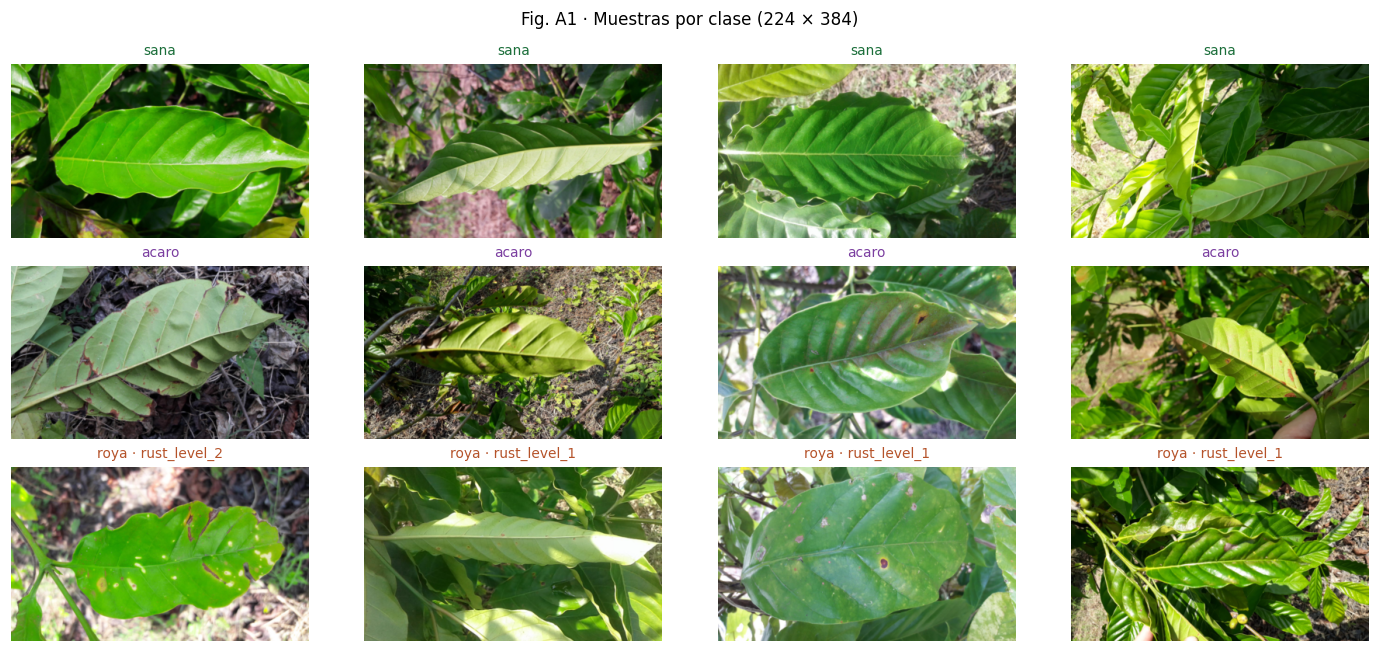

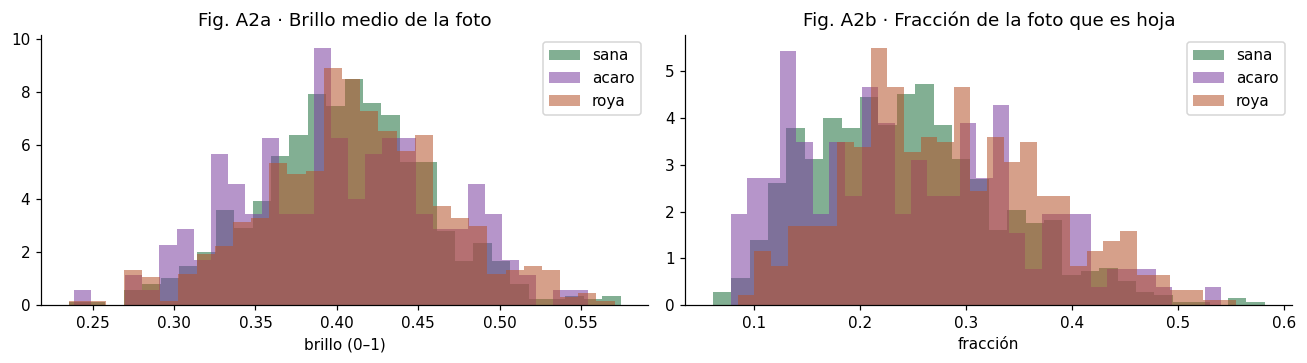

In [5]:
# Celda A3 · EDA: balance, tamaños, muestras por clase, iluminación y fondo
# Resume las clases y las resoluciones, muestra ejemplos y mide brillo y área de hoja por clase.

def area_hoja(fila):
    mk = Image.new("L", (int(fila.ancho0), int(fila.alto0)), 0); d = ImageDraw.Draw(mk)
    for pol in fila.poligonos:
        if len(pol) >= 3: d.polygon(pol, fill=1)
    return np.asarray(mk.resize((96, 54)), dtype=np.float32).mean()

tabla["brillo"] = [IMGS[f].mean() / 255 for f in tabla.fila]
tabla["frac_hoja"] = [area_hoja(r) for r in tabla.itertuples()]
tabla["resolucion"] = tabla.ancho0.astype(str) + "×" + tabla.alto0.astype(str)

print("(a) Balance de clases:")
print(tabla.clase.value_counts().reindex(CLASES).to_frame("fotos").assign(pct=lambda d: (100 * d.fotos / d.fotos.sum()).round(1)).to_string())
print("\n    Niveles dentro de «roya»:", tabla.loc[tabla.clase == "roya", "nivel"].value_counts().sort_index().to_dict())
print("\n(b) Resoluciones de origen:"); print(pd.crosstab(tabla.resolucion, tabla.clase).reindex(columns=CLASES).to_string())
print("\n(d) Brillo medio (0–1) y (e) fracción de la foto ocupada por la hoja, por clase:")
print(tabla.groupby("clase")[["brillo", "frac_hoja"]].describe().loc[CLASES, (slice(None), ["mean", "std", "min", "max"])].round(3).to_string())

fig, axes = plt.subplots(3, 4, figsize=(13, 6))
for i, c in enumerate(CLASES):
    muestra = tabla[tabla.clase == c].sample(4, random_state=SEMILLA)
    for j, r in enumerate(muestra.itertuples()):
        axes[i, j].imshow(IMGS[r.fila]); axes[i, j].axis("off")
        axes[i, j].set_title(f"{c} · {r.nivel}" if c == "roya" else c, fontsize=9, color=COLORES[c])
plt.suptitle("Fig. A1 · Muestras por clase (224 × 384)", fontsize=11); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for c in CLASES:
    ax[0].hist(tabla.loc[tabla.clase == c, "brillo"], bins=30, alpha=0.55, color=COLORES[c], label=c, density=True)
    ax[1].hist(tabla.loc[tabla.clase == c, "frac_hoja"], bins=30, alpha=0.55, color=COLORES[c], label=c, density=True)
ax[0].set_title("Fig. A2a · Brillo medio de la foto"); ax[0].set_xlabel("brillo (0–1)"); ax[0].legend()
ax[1].set_title("Fig. A2b · Fracción de la foto que es hoja"); ax[1].set_xlabel("fracción"); ax[1].legend()
plt.tight_layout(); plt.show()

### Decisiones que deja el EDA

| # | Hallazgo | Decisión |
|---|---|---|
| a | **Desbalance**: sana 791 (50,7 %), roya 602 (38,6 %), ácaro solo 167 (10,7 %). | Pérdida **ponderada por clase** y métricas **por clase** (F1 macro), no solo exactitud. Partición **estratificada**. |
| b | Tres resoluciones (1280 × 720: 479 fotos; 2048 × 1152: 768; 4128 × 2322: 313); el ácaro está sobrerrepresentado en la más alta (70 de 313). | Todas se llevan a 224 × 384 antes de entrar a la red. |
| c | La roya se reconoce por **color** (manchas amarillo-naranja); el ácaro por un **punteado** fino y rojizo. | El aumento de datos **no cambia el tono** (`hue = 0`): cambiar el color borraría justo la señal. Sí se permiten giros, volteos, recortes leves y cambios de brillo. |
| d | El brillo medio va de 0,24 a 0,57 (sol, sombra, hora), igual en las tres clases (0,40–0,41). | Aumento con **brillo y contraste** aleatorios para que la red no dependa de la luz. |
| e | La hoja anotada ocupa en promedio solo **el 25–28 %** de la foto; el resto es suelo, ramas y **otras hojas**, a veces también enfermas. | Riesgo de que la red aprenda del **fondo**. Se verifica con **Grad-CAM** midiendo qué parte de la atención cae dentro de la hoja (A10). |

## A3b · Auditoría de calidad: fotos duplicadas entre plantas

Al alinear las fotos con su fecha (para la rama C) aparecieron **marcas de tiempo idénticas en fotos con nombres distintos**. Se revisó la huella SHA-256 de cada archivo y resultó que **RoCoLe trae la misma foto, byte a byte, bajo nombres de plantas diferentes** (p. ej., `C11P12E1.jpg` = `C12P21E1.jpg`). Esto tiene dos consecuencias:

1. **Fuga entre conjuntos.** La partición por planta no basta: la misma foto puede quedar como «planta 12» en entrenamiento y como «planta 21» en prueba, y la red la reconocería de memoria. Esto afecta también a la Fase 1.
2. **Etiquetas contradictorias.** En varias parejas, la misma foto tiene **clases distintas** (p. ej., ácaro en un nombre y roya en el otro). Ninguna red puede acertar las dos.

**Decisiones.** (i) Los duplicados **exactos** con la misma clase se dejan en **una sola copia**. (ii) Los duplicados exactos con clases **contradictorias** se **retiran** (no se sabe cuál etiqueta es la verdadera). (iii) Además se buscan **casi duplicados** (misma foto recomprimida o recortada) con una huella perceptual (*dHash*); esos no se borran, pero se obligan a caer en el **mismo conjunto** que su pareja. (iv) Si existe la corrida anterior de la rama A (sin esta auditoría), se mide cuánto la favoreció la fuga.

Fotos con al menos un duplicado exacto: 134 en 67 grupos (52 plantas, 7 secciones)
  · misma clase      : 55 grupos → se deja 1 copia, se retiran 55 fotos
  · clase distinta   : 12 grupos → se retiran sus 24 fotos
    combinaciones contradictorias: {'acaro / roya': 11, 'acaro / sana': 1}
  · nivel de roya distinto dentro de la misma clase: 15 grupos (se conservan: la clase coincide)

Corrida anterior: 9 de 236 fotos de prueba tenían su copia exacta en entrenamiento (0 de ellas con la etiqueta contraria).
  exactitud de la corrida anterior en prueba, con copia en entrenamiento : 1.000  (n = 9)
  exactitud de la corrida anterior en prueba, sin copia                  : 0.806  (n = 227)
Casi duplicados entre plantas distintas (dHash ≤ 8 de 256 bits): 0 parejas → mismo conjunto, no se borran

Tabla depurada: 1560 → 1481 fotos · 381 grupos de partición
       fotos   pct
clase             
sana     758  51.2
acaro    155  10.5
roya     568  38.4


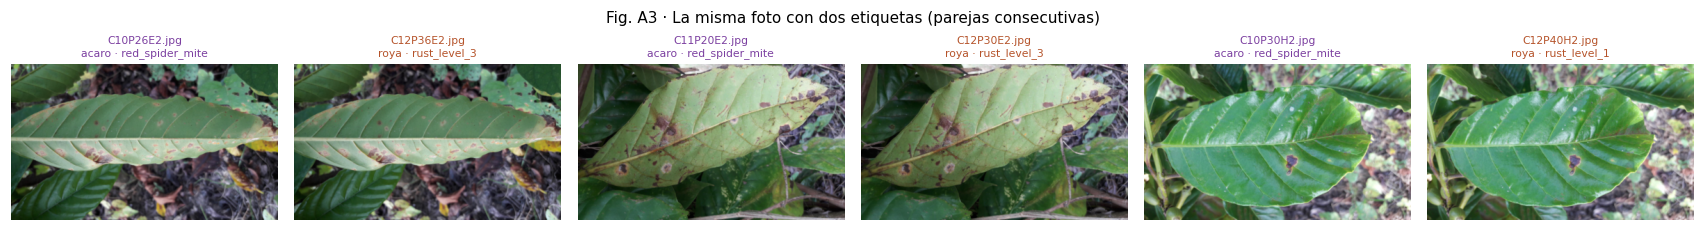

In [6]:
# Celda A3b · Duplicados exactos (SHA-256) y casi duplicados (dHash)
# Calcula la huella de cada foto, agrupa duplicados, retira copias y contradicciones, y arma el grupo de partición.

RUTA_HUELLAS = os.path.join(DATOS, "huellas_fotos.csv")
if os.path.exists(RUTA_HUELLAS):
    huellas = pd.read_csv(RUTA_HUELLAS)
else:
    RUTA_TAR = obtener("RoCoLe-voc.tar.gz"); filas_h = []
    with tarfile.open(RUTA_TAR, "r:gz") as tar:
        for miembro in tar:
            nombre = os.path.basename(miembro.name)
            if nombre.lower().endswith((".jpeg", ".jpg")):
                filas_h.append({"id": os.path.splitext(nombre)[0], "sha256": hashlib.sha256(tar.extractfile(miembro).read()).hexdigest()})
    huellas = pd.DataFrame(filas_h); huellas.to_csv(RUTA_HUELLAS, index=False)
tabla = tabla.merge(huellas, on="id", how="left")
assert tabla.sha256.notna().all(), "Faltan huellas"

g_sha = tabla.groupby("sha256")
tabla["n_copias"] = g_sha.id.transform("size")
tabla["conflicto"] = g_sha.clase.transform("nunique") > 1
tabla["copia_extra"] = tabla.sort_values("archivo").duplicated("sha256").reindex(tabla.index) & ~tabla.conflicto
dup = tabla[tabla.n_copias > 1]
print(f"Fotos con al menos un duplicado exacto: {len(dup)} en {dup.sha256.nunique()} grupos "
      f"({dup.planta.nunique()} plantas, {dup.seccion.nunique()} secciones)")
print(f"  · misma clase      : {dup[~dup.conflicto].sha256.nunique()} grupos → se deja 1 copia, se retiran {int(tabla.copia_extra.sum())} fotos")
print(f"  · clase distinta   : {dup[dup.conflicto].sha256.nunique()} grupos → se retiran sus {int(tabla.conflicto.sum())} fotos")
pares_cl = dup[dup.conflicto].groupby("sha256").clase.apply(lambda c: " / ".join(sorted(c))).value_counts()
if len(pares_cl): print("    combinaciones contradictorias:", pares_cl.to_dict())
print(f"  · nivel de roya distinto dentro de la misma clase: "
      f"{int((dup[~dup.conflicto].groupby('sha256').nivel.nunique() > 1).sum())} grupos (se conservan: la clase coincide)")

RUTA_A_V1 = os.path.join(DATOS, "rama_A_salidas_v1_sin_auditoria.npz")
if os.path.exists(os.path.join(DATOS, "rama_A_salidas.npz")) and not os.path.exists(RUTA_A_V1) \
   and not os.path.exists(os.path.join(DATOS, "rama_A_auditada.flag")):
    shutil.copy(os.path.join(DATOS, "rama_A_salidas.npz"), RUTA_A_V1)
if os.path.exists(RUTA_A_V1):
    v1 = np.load(RUTA_A_V1, allow_pickle=True)
    ant = pd.DataFrame({"id": v1["id"], "conj_v1": v1["conjunto"], "y": v1["y"], "pred_v1": v1["p_img"].argmax(1)}).merge(tabla[["id", "sha256", "conflicto"]], on="id")
    conj_por_sha = ant.groupby("sha256").conj_v1.agg(set)
    ant["gemela_en_entr"] = [len(conj_por_sha[h] - {c}) > 0 and "entrenamiento" in conj_por_sha[h] for h, c in zip(ant.sha256, ant.conj_v1)]
    pr = ant[ant.conj_v1 == "prueba"]
    print(f"\nCorrida anterior: {int(pr.gemela_en_entr.sum())} de {len(pr)} fotos de prueba tenían su copia exacta en entrenamiento "
          f"({int((pr.gemela_en_entr & pr.conflicto).sum())} de ellas con la etiqueta contraria).")
    for nom, sub in [("con copia en entrenamiento", pr[pr.gemela_en_entr]), ("sin copia", pr[~pr.gemela_en_entr])]:
        if len(sub): print(f"  exactitud de la corrida anterior en prueba, {nom:27s}: {accuracy_score(sub.y, sub.pred_v1):.3f}  (n = {len(sub)})")

n_antes = len(tabla)
tabla = tabla[~(tabla.copia_extra | tabla.conflicto)].reset_index(drop=True)

def dhash(a, n=16):                        # huella perceptual: ¿cada píxel es más claro que su vecino de la derecha?
    g = np.asarray(Image.fromarray(a).convert("L").resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()
Hd = np.stack([dhash(IMGS[f]) for f in tabla.fila]).astype(np.float32)
DIST = Hd @ (1 - Hd).T + (1 - Hd) @ Hd.T          # distancia de Hamming entre todas las parejas (256 bits)
UMBRAL_DHASH = 8                                     # ≤ 3 % de bits distintos

padre = list(range(len(tabla)))                      # unión de conjuntos: planta ∪ casi duplicado
def raiz(i):
    while padre[i] != i: padre[i] = padre[padre[i]]; i = padre[i]
    return i
def unir(i, j): padre[raiz(i)] = raiz(j)
for idx in tabla.groupby("planta").indices.values():
    for j in idx[1:]: unir(idx[0], j)
pl_ = tabla.planta.to_numpy()
casi = [(i, j) for i, j in zip(*np.where(np.triu(DIST <= UMBRAL_DHASH, 1))) if pl_[i] != pl_[j]]   # solo entre plantas distintas
if len(casi) <= 0.05 * len(tabla):
    for i, j in casi: unir(i, j)
    print(f"Casi duplicados entre plantas distintas (dHash ≤ {UMBRAL_DHASH} de 256 bits): {len(casi)} parejas → mismo conjunto, no se borran")
else:   # salvaguarda: tantas parejas indican fotos parecidas, no copias; unirlas fundiría la partición en un solo grupo
    print(f"⚠️ {len(casi)} parejas parecidas: demasiadas para ser copias; no se usan para agrupar (revisar el umbral).")
tabla["grupo"] = [raiz(i) for i in range(len(tabla))]
print(f"\nTabla depurada: {n_antes} → {len(tabla)} fotos · {tabla.grupo.nunique()} grupos de partición")
print(tabla.clase.value_counts().reindex(CLASES).to_frame("fotos").assign(pct=lambda d: (100 * d.fotos / d.fotos.sum()).round(1)).to_string())
auditoria_dup = {"fotos_con_duplicado": len(dup), "grupos_exactos": int(dup.sha256.nunique()),
                 "grupos_contradictorios": int(dup[dup.conflicto].sha256.nunique()), "retiradas": n_antes - len(tabla),
                 "casi_duplicados": len(casi), "fotos_finales": len(tabla)}

ej = dup[dup.conflicto].sort_values(["sha256", "archivo"]).head(6)
if len(ej):
    fig, axes = plt.subplots(1, len(ej), figsize=(2.6 * len(ej), 2.2))
    for ax, r in zip(np.atleast_1d(axes), ej.itertuples()):
        ax.imshow(IMGS[r.fila]); ax.axis("off"); ax.set_title(f"{r.archivo}\n{r.clase} · {r.nivel}", fontsize=7, color=COLORES[r.clase])
    plt.suptitle("Fig. A3 · La misma foto con dos etiquetas (parejas consecutivas)", fontsize=10); plt.tight_layout(); plt.show()
if 0 < len(casi) <= 0.05 * len(tabla):                 # verificación visual de los casi duplicados
    muestra_c = casi[:4]
    fig, axes = plt.subplots(len(muestra_c), 2, figsize=(5.4, 1.7 * len(muestra_c)), squeeze=False)
    for k, (i, j) in enumerate(muestra_c):
        for col, ii in enumerate((i, j)):
            r = tabla.iloc[ii]; axes[k, col].imshow(IMGS[r.fila]); axes[k, col].axis("off")
            axes[k, col].set_title(f"{r.archivo} · {r.clase} · d = {int(DIST[i, j])}", fontsize=7)
    plt.suptitle("Fig. A3c · Casi duplicados entre plantas", fontsize=10); plt.tight_layout(); plt.show()

**Lectura de la auditoría.** De las 1.560 fotos, **134 forman 67 grupos de copias exactas** repartidas entre 52 plantas y 7 secciones (sobre todo C11 y C12). En **55 grupos** la clase coincide (en 15 de ellos difiere solo el nivel de roya) y se conserva una copia. En **12 grupos la misma foto tiene dos clases**: 11 veces «ácaro» y «roya», y una vez «ácaro» y «sana» (figura de arriba). Justo la confusión que la rama A no lograba resolver. No hubo casi duplicados entre plantas distintas: el problema son copias exactas. Quedan **1.481 fotos** (sana 758, ácaro 155, roya 568).

**¿Cuánto infló la fuga la corrida anterior?** En la partición sin auditar, **9 de 236 fotos de prueba** tenían su copia exacta en entrenamiento y la red las acertó **todas** (exactitud 1,000, frente a 0,806 en el resto). El efecto en la cifra global es pequeño (9 fotos), pero muestra el mecanismo: la red reconoce de memoria la foto que ya vio. La partición de la Fase 1, hecha solo por planta, tenía el mismo riesgo; se declara como limitación hallada después.

## A4 · Partición 70/15/15 por planta y estratificada

Igual que en la Fase 1, las 4 fotos de una planta van **al mismo conjunto** (si no, la red podría reconocer la luz o la hoja de esa planta en vez de la enfermedad). Tras la auditoría A3b, el grupo es **planta + sus duplicados**: si dos plantas comparten una foto (o una casi idéntica), van juntas. Además se estratifica por clase para que el ácaro quede representado en los tres conjuntos. Se usa `StratifiedGroupKFold` con 20 particiones: 3 para prueba (15 %), 3 para validación (15 %) y 14 para entrenamiento (70 %).

> Resultado: entrenamiento 1.039 fotos (268 plantas), validación 217 (56; 21 ácaros) y prueba 225 (57; 32 ácaros). La Fase 1 usó 60/20/20; la actividad de la Fase 2 pide 70/15/15. Para comparar con la Fase 1 de forma justa, la línea base de la Fase 1 se **recalcula sobre este mismo conjunto de prueba** (A9).

In [7]:
# Celda A4 · Partición por grupo (planta + duplicados), estratificada por clase
# Asigna cada grupo a entrenamiento, validación o prueba (70/15/15) manteniendo el balance de clases.

n_part = 20 if not MODO_PRUEBA else 10
sgkf = StratifiedGroupKFold(n_splits=n_part, shuffle=True, random_state=SEMILLA)
pliegue = np.empty(len(tabla), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(tabla, tabla.y, tabla.grupo)): pliegue[idx] = k
n_te = n_va = 3 if not MODO_PRUEBA else 2
tabla["conjunto"] = np.where(pliegue < n_te, "prueba", np.where(pliegue < n_te + n_va, "validacion", "entrenamiento"))
CONJ = ["entrenamiento", "validacion", "prueba"]
assert tabla.groupby("grupo").conjunto.nunique().max() == 1, "Un grupo quedó en dos conjuntos"
assert tabla.groupby("sha256").conjunto.nunique().max() == 1, "Una foto duplicada quedó en dos conjuntos"
HUELLA_PART = hashlib.sha256("|".join(sorted(tabla.id + ":" + tabla.conjunto)).encode()).hexdigest()[:10]
CKPT = os.path.join(BASE, "checkpoints", f"particion_{HUELLA_PART}"); os.makedirs(CKPT, exist_ok=True)
print(f"Huella de la partición: {HUELLA_PART} · puntos de control en {CKPT}")
resumen_part = pd.crosstab(tabla.conjunto, tabla.clase).reindex(index=CONJ, columns=CLASES)
resumen_part["total"] = resumen_part.sum(axis=1)
resumen_part["% del total"] = (100 * resumen_part.total / resumen_part.total.sum()).round(1)
resumen_part["plantas"] = tabla.groupby("conjunto").planta.nunique().reindex(CONJ)
resumen_part

Huella de la partición: 2a461520b6 · puntos de control en /content/drive/MyDrive/centinela_fase2/checkpoints/particion_2a461520b6


clase,sana,acaro,roya,total,% del total,plantas
conjunto,,,,,,
entrenamiento,535,102,402,1039,70.2,268
validacion,111,21,85,217,14.7,56
prueba,112,32,81,225,15.2,57


## A5 · Dos arquitecturas preentrenadas: ResNet50 frente a EfficientNet-B0

Ambas se entrenaron en **ImageNet** (1,2 millones de fotos naturales). Sus primeras capas ya saben detectar bordes, texturas y manchas de color, que es lo que distingue una hoja enferma. Representan dos filosofías:

- **ResNet50** (He et al., 2016): 50 capas con **conexiones residuales** (atajos que dejan pasar el gradiente sin desvanecerse). Grande y robusta; el estándar del aprendizaje por transferencia.
- **EfficientNet-B0** (Tan y Le, 2019): escala **a la vez** profundidad, ancho y resolución, y usa convoluciones separables. Unas 5 veces menos parámetros: candidata natural para el despliegue en el teléfono del técnico (Fase 3).

La celda mide lo que pide la rúbrica: **parámetros, profundidad, exactitud en ImageNet y velocidad de inferencia** a nuestro tamaño de entrada, en GPU y en CPU (este último aproxima un equipo sin GPU en campo).

In [8]:
# Celda A5 · Construcción de las redes y comparación técnica
# Carga ResNet50 y EfficientNet-B0 preentrenadas y mide parámetros, capas, exactitud ImageNet y velocidad.

ARQS = ["ResNet50", "EfficientNet-B0"]

def construir_backbone(arq):

    fijar_semillas()
    if arq == "ResNet50":
        pesos = models.ResNet50_Weights.IMAGENET1K_V2 if PESOS_IMAGENET else None
        red = models.resnet50(weights=pesos); dim = red.fc.in_features; red.fc = nn.Identity()
    else:
        pesos = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if PESOS_IMAGENET else None
        red = models.efficientnet_b0(weights=pesos); dim = red.classifier[1].in_features; red.classifier = nn.Identity()
    return red, dim, pesos

def bloque_final(backbone, arq):      # lo que se descongela en el ajuste fino
    return backbone.layer4 if arq == "ResNet50" else backbone.features[6:]

def capa_gradcam(backbone, arq):      # último mapa de activación espacial
    return backbone.layer4 if arq == "ResNet50" else backbone.features[-1]

class RedCNN(nn.Module):

    def __init__(self, backbone, dim, n_clases=3, p_dropout=0.3):
        super().__init__()
        self.backbone = backbone
        self.cabeza = nn.Sequential(nn.Dropout(p_dropout), nn.Linear(dim, n_clases))
    def forward(self, x):
        return self.cabeza(self.backbone(x))
    def embedding(self, x):           # z_img para la fusión (rama C)
        return self.backbone(x)

def n_param(mod, solo_entrenables=False):
    return sum(p.numel() for p in mod.parameters() if p.requires_grad or not solo_entrenables)

@torch.no_grad()
def ms_por_imagen(red, dispositivo, lote, reps):
    red = red.to(dispositivo).eval(); x = torch.randn(lote, 3, ALTO, ANCHO, device=dispositivo)
    for _ in range(2): red(x)
    if dispositivo.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps): red(x)
    if dispositivo.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / (reps * lote)

comparacion_arq = []
for arq in ARQS:
    bb, dim, pesos = construir_backbone(arq)
    fila = {"arquitectura": arq, "parámetros (M)": n_param(bb) / 1e6,
            "capas convolucionales": sum(isinstance(mo, nn.Conv2d) for mo in bb.modules()),
            "dim. embedding": dim,
            "parámetros del último bloque (M)": n_param(bloque_final(bb, arq)) / 1e6,
            "exactitud ImageNet top-1 (%)": pesos.meta["_metrics"]["ImageNet-1K"]["acc@1"] if pesos else np.nan,
            "ms/imagen CPU (lote 1)": ms_por_imagen(bb, torch.device("cpu"), 1, 2 if MODO_PRUEBA else 5)}
    if DEVICE.type == "cuda":
        fila["ms/imagen GPU (lote 32)"] = ms_por_imagen(bb, DEVICE, 32, 10)
    comparacion_arq.append(fila); del bb
comparacion_arq = pd.DataFrame(comparacion_arq).set_index("arquitectura").round(2)
comparacion_arq

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 123MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


,parámetros (M),capas convolucionales,dim. embedding,parámetros del último bloque (M),exactitud ImageNet top-1 (%),ms/imagen CPU (lote 1),ms/imagen GPU (lote 32)
arquitectura,,,,,,,
ResNet50,23.51,53,2048,14.96,80.86,266.48,5.06
EfficientNet-B0,4.01,81,1280,3.16,77.69,70.33,1.98


**Lectura de la comparación.** ResNet50 tiene **23,5 M** de parámetros y 53 capas convolucionales; EfficientNet-B0, **4,0 M** y 81 capas (es más profunda pero mucho más delgada). En ImageNet, ResNet50 es algo más exacta (80,9 % frente a 77,7 %). En velocidad, EfficientNet-B0 es **2,3 veces más rápida en CPU** (82 frente a 188 ms por foto) y 2,6 veces en GPU (2,0 frente a 5,3 ms). Para el teléfono del técnico (Fase 3), esa diferencia pesa.

**¿Congelar o reentrenar? Lo que dice la teoría.** Con un conjunto **pequeño** (≈ 1.040 fotos de entrenamiento) y **parecido** a ImageNet (fotos naturales en color), lo recomendado es *Feature Extraction*: congelar la red y entrenar solo la cabeza, porque reentrenar millones de pesos con pocas fotos invita al sobreajuste. Pero hay un matiz: ImageNet no tiene clases de **enfermedades de hojas**, y la diferencia entre un punteado de ácaro y una mancha de roya inicial es un detalle fino que los filtros genéricos quizá no capten. Por eso se prueban **las dos estrategias en las dos arquitecturas** y decide la validación.

## A6 · *Feature Extraction*: la red congelada como extractor de características

Se pasa cada foto **una sola vez** por la red congelada y se guarda su vector de características (2.048 números en ResNet50, 1.280 en EfficientNet-B0). Luego se entrena solo una cabeza pequeña (*Dropout* + capa lineal de 3 salidas) sobre esos vectores, en segundos. Pérdida: entropía cruzada **ponderada por clase**. Parada temprana por pérdida de validación.

En esta estrategia no se usa aumento de datos: como la red no cambia, cada foto produce siempre el mismo vector.

In [9]:
# Celda A6 · Feature Extraction para las dos arquitecturas
# Calcula los vectores de la red congelada para todas las fotos y entrena una cabeza de 3 clases.

MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESV = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def a_tensor_norm(filas_cache):           # uint8 (N,H,W,3) → float normalizado (N,3,H,W)
    x = torch.from_numpy(np.ascontiguousarray(IMGS[filas_cache])).permute(0, 3, 1, 2).float() / 255
    return (x - MEDIA) / DESV

idx = {c: tabla.index[tabla.conjunto == c].to_numpy() for c in CONJ}
Y = {c: torch.tensor(tabla.loc[idx[c], "y"].to_numpy()) for c in CONJ}
conteo = np.bincount(Y["entrenamiento"].numpy(), minlength=3)
PESO_CLASE = torch.tensor(conteo.sum() / (3 * np.maximum(conteo, 1)), dtype=torch.float32)
print("Peso de cada clase en la pérdida:", dict(zip(CLASES, PESO_CLASE.numpy().round(2))))

@torch.no_grad()
def extraer_vectores(backbone, filas_tabla, lote=64):
    backbone = backbone.to(DEVICE).eval(); salida = []
    filas_cache = tabla.loc[filas_tabla, "fila"].to_numpy()
    for i in range(0, len(filas_cache), lote):
        salida.append(backbone(a_tensor_norm(filas_cache[i:i + lote]).to(DEVICE)).float().cpu())
    return torch.cat(salida)

def metricas_val(logits, y):
    pred = logits.argmax(1).numpy()
    return {"perdida": F.cross_entropy(logits, y, weight=PESO_CLASE).item(),
            "exactitud": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}

def entrenar_cabeza(V, dim, epocas=400, paciencia=40):
    fijar_semillas(); cab = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, 3))
    opt = torch.optim.Adam(cab.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss(weight=PESO_CLASE)
    mejor, estado, sin_mejora, hist = 1e9, None, 0, {"train": [], "val": []}
    for ep in range(1, epocas + 1):
        cab.train(); perd = crit(cab(V["entrenamiento"]), Y["entrenamiento"])
        opt.zero_grad(); perd.backward(); opt.step()
        cab.eval()
        with torch.no_grad(): pv = crit(cab(V["validacion"]), Y["validacion"]).item()
        hist["train"].append(perd.item()); hist["val"].append(pv)
        if pv < mejor: mejor, estado, mejor_ep, sin_mejora = pv, copy.deepcopy(cab.state_dict()), ep, 0
        else: sin_mejora += 1
        if sin_mejora >= paciencia: break
    cab.load_state_dict(estado); cab.eval()
    with torch.no_grad(): mv = metricas_val(cab(V["validacion"]), Y["validacion"])
    return cab, hist, mejor_ep, mv

resultados, modelos_fe, vectores = [], {}, {}
for arq in ARQS:
    ruta_v = os.path.join(CKPT, f"vectores_{arq}.pt")
    if os.path.exists(ruta_v) and not MODO_PRUEBA:
        V = torch.load(ruta_v)
    else:
        bb, dim, _ = construir_backbone(arq); t0 = time.time()
        V = {c: extraer_vectores(bb, idx[c]) for c in CONJ}
        print(f"{arq}: vectores calculados en {time.time()-t0:.0f} s"); torch.save(V, ruta_v); del bb
    vectores[arq] = V; dim = V["entrenamiento"].shape[1]
    t0 = time.time(); cab, hist, ep, mv = entrenar_cabeza(V, dim)
    modelos_fe[arq] = cab
    resultados.append({"arquitectura": arq, "estrategia": "Feature Extraction", "época del mínimo": ep,
                       "pérdida val": mv["perdida"], "exactitud val": mv["exactitud"], "F1 macro val": mv["f1_macro"],
                       "parámetros entrenados": n_param(cab), "segundos": time.time() - t0})
pd.DataFrame(resultados).set_index(["arquitectura", "estrategia"]).round(4)

Peso de cada clase en la pérdida: {'sana': np.float32(0.65), 'acaro': np.float32(3.4), 'roya': np.float32(0.86)}


,,época del mínimo,pérdida val,exactitud val,F1 macro val,parámetros entrenados,segundos
arquitectura,estrategia,,,,,,
ResNet50,Feature Extraction,247,0.7551,0.7281,0.6211,6147,10.7554
EfficientNet-B0,Feature Extraction,51,0.7629,0.7189,0.6215,3843,2.9996


## A7 · *Fine-Tuning*: reentrenar el último bloque con aumento de datos

Se parte de la cabeza ya entrenada en A6 y se **descongela el último bloque** de la red (en ResNet50, `layer4`; en EfficientNet-B0, sus dos últimas etapas y la convolución final). El resto sigue congelado. Dos tasas de aprendizaje: **10⁻⁴** para el bloque (cambios pequeños, para no borrar lo aprendido en ImageNet) y **10⁻³** para la cabeza.

**Aumento de datos** (solo en entrenamiento, distinto en cada época): volteo horizontal y vertical (una hoja no tiene «arriba»), rotación de ±15°, recorte aleatorio del 80–100 % del área y cambios de brillo y contraste de ±20 %. **Sin cambios de tono**, porque el color es el síntoma.

**Detalle técnico.** Las capas de *BatchNorm* del tramo congelado se mantienen en modo evaluación. Si no, sus estadísticas de ImageNet se reescribirían con lotes de 32 fotos de café aunque sus pesos estén congelados.

**Puntos de control.** Al final de cada época se guarda todo en Drive (red, optimizador, historial y mejor estado). Si Colab se desconecta, al volver a ejecutar la celda **continúa desde la última época**; si el entrenamiento ya terminó, lo carga sin repetirlo.

ResNet50: punto de control encontrado (época 10, terminado=True)
EfficientNet-B0: punto de control encontrado (época 9, terminado=True)


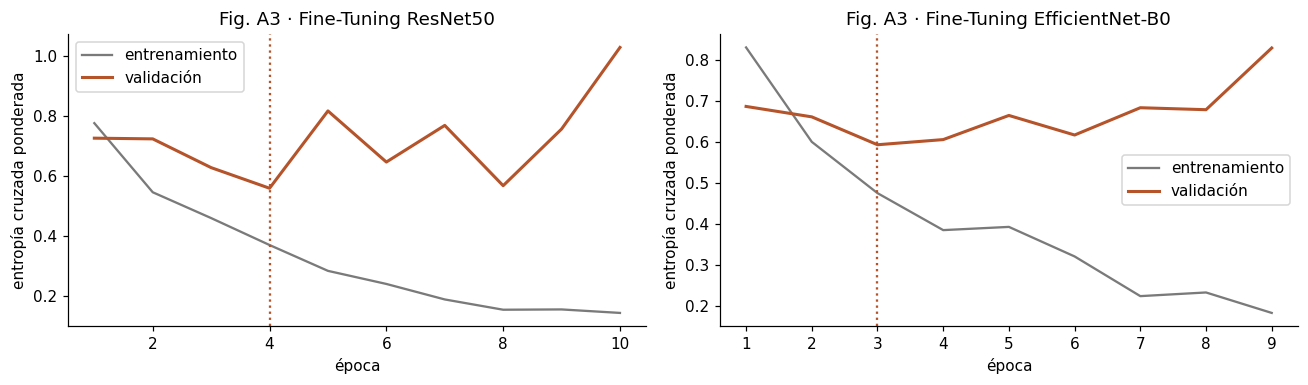

In [10]:
# Celda A7 · Fine-Tuning del último bloque con aumento de datos y puntos de control
# Descongela el último bloque, entrena con aumento y parada temprana, y guarda/reanuda desde Drive.

AUMENTO = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation(15)], p=0.5),
    T.RandomResizedCrop((ALTO, ANCHO), scale=(0.8, 1.0), ratio=(1.55, 1.9), antialias=True),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.0)])

class FotosCafe(torch.utils.data.Dataset):
    def __init__(self, filas_tabla, aumentar):
        self.filas = tabla.loc[filas_tabla, "fila"].to_numpy(); self.y = tabla.loc[filas_tabla, "y"].to_numpy()
        self.aumentar = aumentar
    def __len__(self): return len(self.filas)
    def __getitem__(self, i):
        x = torch.from_numpy(np.ascontiguousarray(IMGS[self.filas[i]])).permute(2, 0, 1)    # uint8 (3,H,W)
        if self.aumentar: x = AUMENTO(x)
        x = (x.float() / 255 - MEDIA[0]) / DESV[0]
        return x, self.y[i]

def cargador(conj, aumentar, lote=32):
    g = torch.Generator().manual_seed(SEMILLA)
    return torch.utils.data.DataLoader(FotosCafe(idx[conj], aumentar), batch_size=lote, shuffle=aumentar,
                                       num_workers=2, generator=g, pin_memory=DEVICE.type == "cuda")

def modo_entrenamiento(red):
    red.train()
    for mo in red.modules():      # BatchNorm del tramo congelado: conservar las estadísticas de ImageNet
        if isinstance(mo, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mo.parameters()):
            mo.eval()

@torch.no_grad()
def evaluar(red, cargador_):
    red.eval(); logits, ys = [], []
    for x, y in cargador_:
        logits.append(red(x.to(DEVICE)).float().cpu()); ys.append(y)
    return torch.cat(logits), torch.cat(ys)

EPOCAS_FT = 25 if not MODO_PRUEBA else 2
PACIENCIA_FT = 6

def ajuste_fino(arq):
    ruta = os.path.join(CKPT, f"ft_{arq}.pt")
    bb, dim, _ = construir_backbone(arq)
    red = RedCNN(bb, dim); red.cabeza[1].load_state_dict(modelos_fe[arq][1].state_dict())   # cabeza de A6
    for p in red.backbone.parameters(): p.requires_grad = False
    for p in bloque_final(red.backbone, arq).parameters(): p.requires_grad = True
    red = red.to(DEVICE)
    opt = torch.optim.Adam([{"params": [p for p in red.backbone.parameters() if p.requires_grad], "lr": 1e-4},
                            {"params": red.cabeza.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    crit = nn.CrossEntropyLoss(weight=PESO_CLASE.to(DEVICE))
    estado = {"epoca": 0, "hist": {"train": [], "val": []}, "mejor": 1e9, "mejor_ep": 0, "mejor_estado": None,
              "terminado": False, "segundos": 0.0}
    if os.path.exists(ruta) and not MODO_PRUEBA:                     # reanudar o reutilizar
        guardado = torch.load(ruta, map_location=DEVICE, weights_only=False)
        red.load_state_dict(guardado["red"]); opt.load_state_dict(guardado["opt"]); estado = guardado["estado"]
        print(f"{arq}: punto de control encontrado (época {estado['epoca']}, terminado={estado['terminado']})")
    dl_tr, dl_va = cargador("entrenamiento", True), cargador("validacion", False)
    sin_mejora = estado["epoca"] - estado["mejor_ep"]
    while not estado["terminado"] and estado["epoca"] < EPOCAS_FT:
        t0 = time.time(); ep = estado["epoca"] + 1; fijar_semillas(SEMILLA + ep)
        modo_entrenamiento(red); acum, n = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            perd = crit(red(x), y)                 # 1 forward · 2 pérdida
            opt.zero_grad()                        # 3 limpiar gradientes
            perd.backward()                        # 4 retropropagación
            opt.step()                             # 5 actualizar
            acum += perd.item() * len(y); n += len(y)
        lv, yv = evaluar(red, dl_va); pv = F.cross_entropy(lv, yv, weight=PESO_CLASE).item()
        estado["hist"]["train"].append(acum / n); estado["hist"]["val"].append(pv)
        if pv < estado["mejor"]:
            estado.update(mejor=pv, mejor_ep=ep, mejor_estado={k: v.detach().cpu().clone() for k, v in red.state_dict().items()}); sin_mejora = 0
        else: sin_mejora += 1
        estado["epoca"] = ep; estado["segundos"] += time.time() - t0
        estado["terminado"] = sin_mejora >= PACIENCIA_FT or ep >= EPOCAS_FT
        torch.save({"red": red.state_dict(), "opt": opt.state_dict(), "estado": estado}, ruta)   # punto de control
        print(f"  {arq} · época {ep:2d} · pérdida entren. {acum/n:.4f} · val {pv:.4f} · {time.time()-t0:.0f} s")
    red.load_state_dict(estado["mejor_estado"]); red.eval()
    lv, yv = evaluar(red, dl_va); mv = metricas_val(lv, yv)
    return red, estado, mv

modelos_ft, estados_ft = {}, {}
for arq in ARQS:
    red, est, mv = ajuste_fino(arq)
    modelos_ft[arq], estados_ft[arq] = red.cpu(), est
    resultados.append({"arquitectura": arq, "estrategia": "Fine-Tuning", "época del mínimo": est["mejor_ep"],
                       "pérdida val": mv["perdida"], "exactitud val": mv["exactitud"], "F1 macro val": mv["f1_macro"],
                       "parámetros entrenados": n_param(red, solo_entrenables=True), "segundos": est["segundos"]})
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, arq in zip(axes, ARQS):
    h = estados_ft[arq]["hist"]; ep = np.arange(1, len(h["train"]) + 1)
    ax.plot(ep, h["train"], color="#7a7a7a", label="entrenamiento"); ax.plot(ep, h["val"], color="#b5532a", lw=2, label="validación")
    ax.axvline(estados_ft[arq]["mejor_ep"], ls=":", color="#b5532a"); ax.set_title(f"Fig. A3 · Fine-Tuning {arq}")
    ax.set_xlabel("época"); ax.set_ylabel("entropía cruzada ponderada"); ax.legend()
plt.tight_layout(); plt.show()

## A8 · Elección del modelo en validación

Las cuatro combinaciones se comparan con el **F1 macro de validación** (promedio del F1 de las tres clases, para que el ácaro pese igual que las otras. La prueba no se usa para elegir: se mira una sola vez, en A9.

In [11]:
# Celda A8 · Tabla 2 × 2 (arquitectura × estrategia) y elección por F1 macro de validación
# Junta las cuatro corridas y elige la de mayor F1 macro en validación (desempate: menor pérdida).

tabla_modelos = pd.DataFrame(resultados).set_index(["arquitectura", "estrategia"])
orden = tabla_modelos.sort_values(["F1 macro val", "pérdida val"], ascending=[False, True])
ARQ_FINAL, ESTRATEGIA_FINAL = orden.index[0]
print(f"Modelo elegido: {ARQ_FINAL} · {ESTRATEGIA_FINAL}")

if ESTRATEGIA_FINAL == "Fine-Tuning":
    modelo_A = modelos_ft[ARQ_FINAL]
else:
    bb, dim, _ = construir_backbone(ARQ_FINAL); modelo_A = RedCNN(bb, dim)
    modelo_A.cabeza[1].load_state_dict(modelos_fe[ARQ_FINAL][1].state_dict())
modelo_A = modelo_A.to(DEVICE).eval()
tabla_modelos.round(4)

Modelo elegido: ResNet50 · Fine-Tuning


,,época del mínimo,pérdida val,exactitud val,F1 macro val,parámetros entrenados,segundos
arquitectura,estrategia,,,,,,
ResNet50,Feature Extraction,247,0.7551,0.7281,0.6211,6147,10.7554
EfficientNet-B0,Feature Extraction,51,0.7629,0.7189,0.6215,3843,2.9996
ResNet50,Fine-Tuning,4,0.5599,0.8525,0.7669,14970883,114.2938
EfficientNet-B0,Fine-Tuning,3,0.5933,0.8018,0.7034,3159583,85.9381


**Lectura de la tabla 2 × 2.**

- **Con la red congelada, las dos arquitecturas empatan**: F1 macro de validación 0,621 (ResNet50) y 0,622 (EfficientNet-B0), con exactitud cercana a 0,72. Los filtros genéricos de ImageNet separan bien sana de enferma, pero no ácaro de roya.
- **Reentrenar el último bloque mejora mucho**: ResNet50 sube a F1 **0,767** (exactitud 0,853) y EfficientNet-B0 a 0,703. Son **+0,15 y +0,08** sobre su versión congelada.
- **Esto contradice la regla general** («con pocos datos, congelar»), y también el resultado del ejemplo del curso, donde ganaba congelar. La razón es que ImageNet no tiene enfermedades de hojas: el punteado del ácaro y las pústulas de roya son detalles finos que los filtros genéricos no capturan y que el último bloque sí aprende a ver. El costo es real: 15 M de parámetros entrenados frente a 6 mil, y 114 s frente a 11 s.
- **El sobreajuste aparece pronto y la parada temprana lo corta** (Fig. A3). En ResNet50 la pérdida de entrenamiento cae de 0,78 a 0,15, mientras la de validación toca su mínimo en la **época 4** (0,560) y luego oscila entre 0,57 y 1,03; el entrenamiento se detiene en la época 10 y se conserva la 4. Con solo 217 fotos de validación, la curva es ruidosa: una decena de ácaros mal clasificados mueve la pérdida.

**Elección: ResNet50 con *Fine-Tuning*.** EfficientNet-B0 queda como alternativa para el despliegue en la Fase 3: es 2,3 veces más rápida en CPU y pierde 0,06 de F1.

## A9 · Evaluación única en prueba

Tres lecturas: (1) la matriz de confusión de **3 clases**; (2) la versión **binaria** —sana frente a enferma, sumando ácaro y roya— para compararla con la Fase 1 sobre **este mismo conjunto de prueba**, con la misma regla de umbral (avisar al menos 9 de cada 10 enfermas en validación); (3) los escapes **por nivel de roya**, la debilidad de la Fase 1.

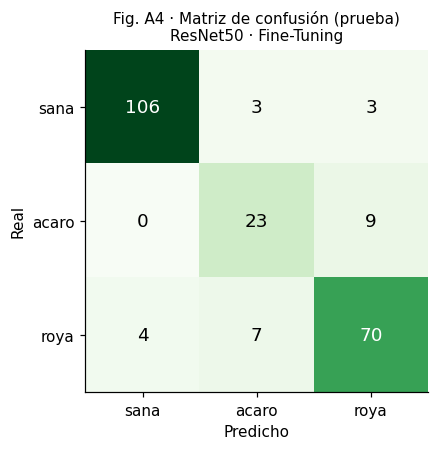

              precision    recall  f1-score   support

        sana      0.964     0.946     0.955       112
       acaro      0.697     0.719     0.708        32
        roya      0.854     0.864     0.859        81

    accuracy                          0.884       225
   macro avg      0.838     0.843     0.841       225
weighted avg      0.886     0.884     0.885       225


Sana frente a enferma, en el mismo conjunto de prueba:


,exactitud,precisión enf.,recall enf.,F1 enf.,AUC,FN,FP
"CNN ResNet50 · umbral 0.71 (recall ≥ 0,90 en val.)",0.938,0.954,0.920,0.937,0.986,9.0,5.0
"Fase 1 · regla frac_roya > 0.0003 (recall ≥ 0,90 en val.)",0.804,0.738,0.947,0.829,0.902,6.0,38.0


Escapes por nivel (umbral binario de la CNN):


,hojas,avisadas,se escapan,% que se escapa
nivel,,,,
red_spider_mite,32,31,1,3.1
rust_level_1,51,43,8,15.7
rust_level_2,15,15,0,0.0
rust_level_3,9,9,0,0.0
rust_level_4,6,6,0,0.0


In [12]:
# Celda A9 · Prueba: matriz 3×3, métricas por clase, comparación binaria con la Fase 1 y escapes por severidad
# Evalúa una sola vez el modelo elegido en prueba y lo compara con la regla de la Fase 1.

lp, yp = evaluar(modelo_A, cargador("prueba", False)); lv, yv = evaluar(modelo_A, cargador("validacion", False))
prob_te, prob_va = F.softmax(lp, 1).numpy(), F.softmax(lv, 1).numpy()
pred_te = prob_te.argmax(1); y_te = yp.numpy()

cm = confusion_matrix(y_te, pred_te, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.8, 4.2)); ax.imshow(cm, cmap="Greens")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks(range(3), CLASES); ax.set_yticks(range(3), CLASES); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title(f"Fig. A4 · Matriz de confusión (prueba)\n{ARQ_FINAL} · {ESTRATEGIA_FINAL}", fontsize=10)
plt.tight_layout(); plt.show()
print(classification_report(y_te, pred_te, labels=[0, 1, 2], target_names=CLASES, digits=3, zero_division=0))

# ── Comparación binaria con la Fase 1 en el MISMO conjunto de prueba ─────────────────────────────
def umbral_recall(p_enf_val, y_enf_val, objetivo=0.90):
    cands = [u for u in np.round(np.arange(0.05, 0.951, 0.01), 2) if (p_enf_val[y_enf_val == 1] >= u).mean() >= objetivo]
    return max(cands) if cands else 0.5
def metricas_bin(y, yhat, score=None):
    p, r, f1, _ = precision_recall_fscore_support(y, yhat, labels=[1], zero_division=0)
    cmb = confusion_matrix(y, yhat, labels=[1, 0])
    return {"exactitud": accuracy_score(y, yhat), "precisión enf.": p[0], "recall enf.": r[0], "F1 enf.": f1[0],
            "AUC": roc_auc_score(y, score) if score is not None else np.nan, "FN": int(cmb[0, 1]), "FP": int(cmb[1, 0])}

yb_te, yb_va = (y_te > 0).astype(int), (yv.numpy() > 0).astype(int)
p_enf_te, p_enf_va = 1 - prob_te[:, 0], 1 - prob_va[:, 0]
U_CNN = umbral_recall(p_enf_va, yb_va)
comparacion_f1 = {f"CNN {ARQ_FINAL} · umbral {U_CNN:.2f} (recall ≥ 0,90 en val.)": metricas_bin(yb_te, (p_enf_te >= U_CNN).astype(int), p_enf_te)}

ruta_rasgos = os.path.join(DATOS_F1, "rasgos_rocole.csv")
if os.path.exists(ruta_rasgos):               # regla de la Fase 1 (fracción de píxeles color roya), recalculada aquí
    fr = tabla[["id", "conjunto"]].merge(pd.read_csv(ruta_rasgos)[["id", "frac_roya"]], on="id", how="left")
    fv, ft_ = fr.loc[idx["validacion"], "frac_roya"].to_numpy(), fr.loc[idx["prueba"], "frac_roya"].to_numpy()
    cands = [c for c in np.quantile(fv, np.linspace(0.01, 0.99, 99)) if (fv[yb_va == 1] > c).mean() >= 0.90]
    u_fr = float(max(cands)) if cands else float(fv.min()) - 1e-9
    comparacion_f1[f"Fase 1 · regla frac_roya > {u_fr:.4f} (recall ≥ 0,90 en val.)"] = metricas_bin(yb_te, (ft_ > u_fr).astype(int), ft_)
else:
    print("Aviso: no se encontró rasgos_rocole.csv de la Fase 1 en Drive; se omite la comparación directa.")
comparacion_f1 = pd.DataFrame(comparacion_f1).T.round(3)
print("\nSana frente a enferma, en el mismo conjunto de prueba:"); display(comparacion_f1)

# ── ¿Qué hojas enfermas se escapan? (por nivel original) ─────────────────────────────────────────
ev = tabla.loc[idx["prueba"], ["archivo", "clase", "nivel"]].assign(pred=[CLASES[k] for k in pred_te], p_enf=p_enf_te)
ev["avisada"] = ev.p_enf >= U_CNN
escapes = ev[ev.clase != "sana"].groupby("nivel").agg(hojas=("avisada", "size"), avisadas=("avisada", "sum"))
escapes["se escapan"] = escapes.hojas - escapes.avisadas
escapes["% que se escapa"] = (100 * escapes["se escapan"] / escapes.hojas).round(1)
print("Escapes por nivel (umbral binario de la CNN):"); display(escapes)

26 errores de 225 fotos de prueba


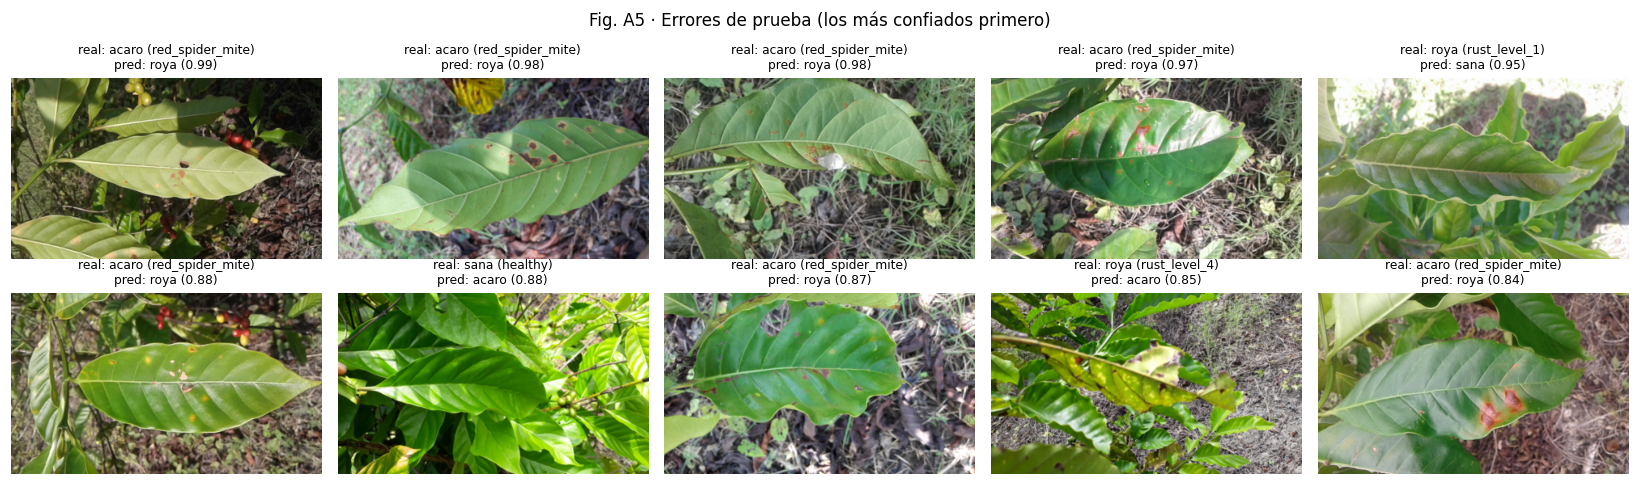

In [13]:
# Celda A9b · Errores con ejemplos visuales
# Muestra hasta 10 fotos de prueba mal clasificadas, con su clase real, la predicha y la confianza.

errores = np.where(pred_te != y_te)[0]
print(f"{len(errores)} errores de {len(y_te)} fotos de prueba")
if len(errores):
    sel = errores[np.argsort(-prob_te[errores].max(1))][:10]
    filas_c = tabla.loc[idx["prueba"][sel], "fila"].to_numpy()
    fig, axes = plt.subplots(2, 5, figsize=(15, 4.6))
    for ax in axes.ravel(): ax.axis("off")
    for ax, k, fc in zip(axes.ravel(), sel, filas_c):
        r = tabla.loc[idx["prueba"][k]]
        ax.imshow(IMGS[fc]); ax.set_title(f"real: {r.clase} ({r.nivel})\npred: {CLASES[pred_te[k]]} ({prob_te[k].max():.2f})", fontsize=8)
    plt.suptitle("Fig. A5 · Errores de prueba (los más confiados primero)", fontsize=11); plt.tight_layout(); plt.show()

In [14]:
# Celda A9c · Menú de umbrales para la alerta binaria (información para el cliente)
# Muestra recall, precisión, alarmas omitidas y falsas alarmas de la CNN a varios umbrales, en validación y en prueba.

menu = []
for u in [0.20, 0.30, 0.40, 0.50, 0.60, U_CNN]:
    for conj, pe, yb in [("validación", p_enf_va, yb_va), ("prueba", p_enf_te, yb_te)]:
        mb = metricas_bin(yb, (pe >= u).astype(int))
        menu.append({"umbral": u, "conjunto": conj, "recall enf.": mb["recall enf."], "precisión enf.": mb["precisión enf."],
                     "alarmas omitidas (FN)": mb["FN"], "falsas alarmas (FP)": mb["FP"]})
pd.DataFrame(menu).set_index(["umbral", "conjunto"]).round(3)

recall enf.  precisión enf.  alarmas omitidas (FN)  \
umbral conjunto                                                         
0.20   validación        0.972           0.792                      3   
       prueba            0.991           0.824                      1   
0.30   validación        0.972           0.837                      3   
       prueba            0.991           0.848                      1   
0.40   validación        0.962           0.879                      4   
       prueba            0.982           0.895                      2   
0.50   validación        0.925           0.933                      8   
       prueba            0.965           0.940                      4   
0.60   validación        0.915           0.951                      9   
       prueba            0.956           0.947                      5   
0.71   validación        0.906           0.970                     10   
       prueba            0.920           0.954                      9   

                   falsas alarmas (FP)  
umbral conjunto                         
0.20   validación                   27  
       prueba                       24  
0.30   validación                   20  
       prueba                       20  
0.40   validación                   14  
       prueba                       13  
0.50   validación                    7  
       prueba                        7  
0.60   validación                    5  
       prueba                        6  
0.71   validación                    3  
       prueba                        5

**Lectura de la prueba.**

**Tres clases.** Exactitud **0,884** y F1 macro **0,841**. Por clase: sana F1 **0,955**, roya **0,859** y ácaro **0,708**. La matriz (Fig. A4) muestra que sano frente a enfermo está casi resuelto (solo 6 sanas mal clasificadas y 4 royas tomadas por sanas); la confusión que queda es **ácaro frente a roya**: 9 ácaros se predicen como roya y 7 royas como ácaro. Los errores más confiados (Fig. A5) son ácaros con **manchas pardas** que se parecen a lesiones de roya: el mismo tipo de foto que en RoCoLe aparecía con las dos etiquetas (A3b).

**Antes y después de la auditoría.** Sin auditar, la misma red daba F1 macro 0,701 y F1 del ácaro 0,386. La mejora (+0,14 y +0,32) **no es comparable uno a uno**: cambió la partición y se retiraron de prueba las 24 fotos contradictorias, que son las más difíciles. Lo que sí se puede afirmar es que entrenar con 12 parejas que se contradicen confundía justo la frontera ácaro–roya, y que la cifra anterior no medía bien al modelo.

**Sana frente a enferma, contra la Fase 1, en el mismo conjunto de prueba:**

| | Regla de la Fase 1 (`frac_roya`) | CNN ResNet50 ajustada |
|---|---|---|
| AUC (qué tan bien ordena) | 0,902 | **0,986** |
| Falsas alarmas (de 112 sanas) | 38 | **5** |
| Alarmas omitidas (de 113 enfermas) | **6** | 9 |
| *Recall* «enferma» | **0,947** | 0,920 |
| Precisión «enferma» | 0,738 | **0,954** |

Las dos cumplen la meta de avisar al menos 9 de cada 10 hojas enfermas. La diferencia está en el costo: la regla de la Fase 1 lo logra con **38 falsas alarmas** (una de cada tres sanas), la CNN con **5**. Para el técnico, eso es visitar 43 plantas sanas menos por cada 225 hojas. El umbral elegido en validación (0,71) se sostuvo en prueba. El menú de umbrales (A9c) muestra la alternativa: con umbral 0,5, el *recall* sube a 0,965 (4 omitidas) a cambio de 7 falsas alarmas.

**Escapes por severidad.** La roya de **nivel 2, 3 y 4 se detecta toda** (30 de 30) y el ácaro casi todo (31 de 32 avisados como enfermos, aunque a veces con la clase equivocada). Se escapan **8 de 51 hojas con roya 1** (16 %, frente al 21 % de la Fase 1 en su propio conjunto de prueba). En la Fig. A5, una roya 1 se predice «sana» con 0,95: sus lesiones son puntos diminutos que, al reducir la foto de 2.048 a 384 píxeles de ancho, prácticamente desaparecen. **La resolución limita la detección de la roya inicial**, y es una mejora concreta para la Fase 3 (más resolución o recortes de la hoja).

## A10 · Grad-CAM: ¿la red mira la hoja o el fondo?

**Grad-CAM** (Selvaraju et al., 2017) colorea las zonas de la foto que más empujaron la decisión: toma el último mapa de activación de la red y pondera cada canal por cuánto cambia la clase predicha cuando ese canal cambia (su gradiente). Rojo = muy influyente.

Además de mirarlo, se **mide**: para cada foto de prueba se calcula qué fracción de la «masa» del Grad-CAM cae **dentro del contorno anotado de la hoja**, y se compara con la fracción de la foto que ocupa la hoja (lo que daría una atención al azar). Si la red mira la hoja, la primera debe ser claramente mayor.

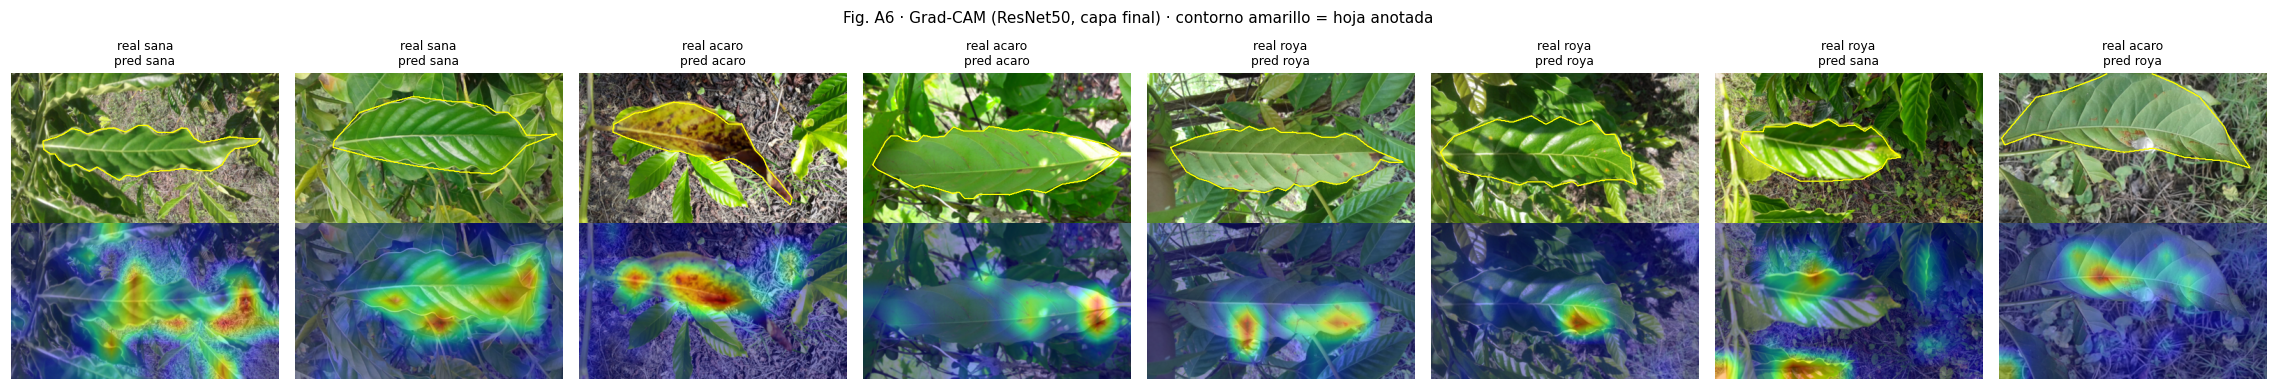

Masa del Grad-CAM dentro de la hoja frente a la fracción de la foto que es hoja (prueba).
razón > 1: la red mira la hoja más de lo que lo haría al azar.


,masa_en_hoja,area_hoja,razón
clase,,,
sana,0.432,0.240,1.908
acaro,0.535,0.254,2.202
roya,0.567,0.299,1.978
todas,0.495,0.263,1.975


In [15]:
# Celda A10 · Grad-CAM cualitativo (por clase) y cuantitativo (atención dentro de la hoja)
# Calcula Grad-CAM con ganchos en el último mapa convolucional y mide su masa dentro del contorno.

capa = capa_gradcam(modelo_A.backbone, ARQ_FINAL)
_act, _grad = {}, {}
def _gancho(mo, entrada, salida):             # guarda la activación y, al retropropagar, su gradiente
    _act["v"] = salida
    salida.register_hook(lambda g: _grad.__setitem__("v", g))
h1 = capa.register_forward_hook(_gancho)

def grad_cam(fila_cache, clase=None):
    modelo_A.eval(); modelo_A.zero_grad()
    for p in modelo_A.parameters(): p.requires_grad_(True)
    x = a_tensor_norm(np.array([fila_cache])).to(DEVICE)
    logits = modelo_A(x); c = int(logits.argmax(1)) if clase is None else clase
    logits[0, c].backward()
    A, G = _act["v"][0].detach(), _grad["v"][0].detach()
    cam = F.relu((G.mean((1, 2))[:, None, None] * A).sum(0))
    cam = F.interpolate(cam[None, None], size=(ALTO, ANCHO), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), c

def mascara_hoja(r):
    mk = Image.new("L", (ANCHO, ALTO), 0); d = ImageDraw.Draw(mk); sx, sy = ANCHO / r.ancho0, ALTO / r.alto0
    for pol in r.poligonos:
        if len(pol) >= 3: d.polygon([(x * sx, y * sy) for x, y in pol], fill=1)
    return np.asarray(mk, dtype=bool)

# Cualitativo: 2 aciertos por clase + 2 errores
aciertos = [np.where((pred_te == y_te) & (y_te == k))[0][:2] for k in range(3)]
mostrar = list(np.concatenate(aciertos)) + list(np.where(pred_te != y_te)[0][:2])
fig, axes = plt.subplots(2, len(mostrar), figsize=(2.6 * len(mostrar), 3.6))
for j, k in enumerate(mostrar):
    r = tabla.loc[idx["prueba"][k]]; cam, c = grad_cam(r.fila)
    axes[0, j].imshow(IMGS[r.fila]); axes[0, j].contour(mascara_hoja(r), levels=[0.5], colors="yellow", linewidths=0.8)
    axes[0, j].set_title(f"real {r.clase}\npred {CLASES[c]}", fontsize=8)
    axes[1, j].imshow(IMGS[r.fila]); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    for a in axes[:, j]: a.axis("off")
plt.suptitle(f"Fig. A6 · Grad-CAM ({ARQ_FINAL}, capa final) · contorno amarillo = hoja anotada", fontsize=10)
plt.tight_layout(); plt.show()

# Cuantitativo: masa del Grad-CAM dentro de la hoja frente a la fracción de área de la hoja
filas_gc = []
for k, i_tab in enumerate(idx["prueba"]):
    r = tabla.loc[i_tab]; cam, c = grad_cam(r.fila); mk = mascara_hoja(r)
    filas_gc.append({"clase": r.clase, "acierto": c == r.y, "masa_en_hoja": cam[mk].sum() / (cam.sum() + 1e-8), "area_hoja": mk.mean()})
h1.remove()
for p in modelo_A.parameters(): p.requires_grad_(False)
gc = pd.DataFrame(filas_gc); gc["razón"] = gc.masa_en_hoja / gc.area_hoja
resumen_gc = gc.groupby("clase")[["masa_en_hoja", "area_hoja", "razón"]].mean().reindex(CLASES)
resumen_gc.loc["todas"] = gc[["masa_en_hoja", "area_hoja", "razón"]].mean()
print("Masa del Grad-CAM dentro de la hoja frente a la fracción de la foto que es hoja (prueba).")
print("razón > 1: la red mira la hoja más de lo que lo haría al azar.")
resumen_gc.round(3)

**Lectura del Grad-CAM.** **La red mira la hoja.** En promedio, el **49,5 %** de la atención cae dentro del contorno de la hoja anotada, que ocupa solo el **26 %** de la foto: **casi 2 veces** más de lo que daría el azar, y parecido en las tres clases (1,91 sana, 2,20 ácaro, 1,98 roya). En los aciertos de ácaro y roya el mapa se concentra sobre las manchas de la lámina (Fig. A6). En las sanas la atención es más difusa: no hay una lesión que mirar.

Los errores muestran dos modos de falla. En «real roya, predicho sana», la atención se reparte sobre el **fondo y otras hojas**: la red no encontró la lesión, coherente con la roya 1 diminuta. En «real ácaro, predicho roya», la red sí mira la hoja y sus manchas, pero las interpreta como roya: es la frontera ácaro–roya que ni las etiquetas de RoCoLe resuelven del todo. Además, la foto contiene otras hojas, a veces enfermas de otra cosa, y la etiqueta describe solo la anotada. Para el uso real se recomienda que el técnico **encuadre una sola hoja** o que la Fase 3 recorte la hoja antes de clasificarla.

## A11 · Pesos entrenados y salidas para la fusión

Se guardan en Drive: (1) los **pesos** del modelo elegido (`.pth`, el `state_dict` de PyTorch), con un archivo de metadatos (arquitectura, clases, tamaño de entrada, normalización); (2) para **las 1.481 fotos depuradas**, el *embedding* de la penúltima capa (`z_img`) y las probabilidades de las 3 clases, junto con el conjunto al que pertenece cada foto. La rama C los reutiliza sin volver a pasar las fotos por la CNN.

In [16]:
# Celda A11 · Guardar pesos .pth, metadatos, embeddings z_img y cifras de la rama A
# Exporta el modelo elegido y sus salidas para todas las fotos; resume las cifras para el informe.

nombre = f"cnn_{ARQ_FINAL.replace('-', '').lower()}_{'ft' if ESTRATEGIA_FINAL == 'Fine-Tuning' else 'fe'}"
torch.save(modelo_A.state_dict(), os.path.join(PESOS, nombre + ".pth"))
json.dump({"arquitectura": ARQ_FINAL, "estrategia": ESTRATEGIA_FINAL, "clases": CLASES, "entrada": [3, ALTO, ANCHO],
           "media": MEDIA.flatten().tolist(), "desv": DESV.flatten().tolist(), "umbral_enferma": U_CNN},
          open(os.path.join(PESOS, nombre + ".json"), "w"), ensure_ascii=False, indent=1)

@torch.no_grad()
def salidas_todas(lote=64):
    modelo_A.eval(); Z, P = [], []
    for i in range(0, len(tabla), lote):
        x = a_tensor_norm(tabla.fila.to_numpy()[i:i + lote]).to(DEVICE)
        z = modelo_A.embedding(x); Z.append(z.float().cpu()); P.append(F.softmax(modelo_A.cabeza(z), 1).float().cpu())
    return torch.cat(Z).numpy(), torch.cat(P).numpy()
Z_IMG, P_IMG = salidas_todas()
open(os.path.join(DATOS, "rama_A_auditada.flag"), "w").write(HUELLA_PART)
np.savez_compressed(os.path.join(DATOS, "rama_A_salidas.npz"), id=tabla.id.to_numpy(), archivo=tabla.archivo.to_numpy(),
                    conjunto=tabla.conjunto.to_numpy(), y=tabla.y.to_numpy(), nivel=tabla.nivel.to_numpy(), z_img=Z_IMG, p_img=P_IMG)

def limpio(o):
    if isinstance(o, dict): return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpio(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    return o
cifras_A = {"auditoria_duplicados": auditoria_dup, "huella_particion": HUELLA_PART, "particion": resumen_part.reset_index().to_dict("records"),
            "arquitecturas": comparacion_arq.reset_index().to_dict("records"),
            "modelos": tabla_modelos.reset_index().to_dict("records"),
            "elegido": [ARQ_FINAL, ESTRATEGIA_FINAL], "umbral_binario": U_CNN,
            "reporte_prueba": classification_report(y_te, pred_te, labels=[0, 1, 2], target_names=CLASES, output_dict=True, zero_division=0),
            "matriz": cm.tolist(), "binaria_vs_fase1": comparacion_f1.reset_index().to_dict("records"),
            "escapes_por_nivel": escapes.reset_index().to_dict("records"), "gradcam": resumen_gc.reset_index().to_dict("records")}
json.dump(limpio(cifras_A), open(os.path.join(BASE, "cifras_rama_A.json"), "w"), ensure_ascii=False, indent=1)
print(f"Pesos: {os.path.join(PESOS, nombre + '.pth')}  ({os.path.getsize(os.path.join(PESOS, nombre + '.pth'))/1e6:.1f} MB)")
print(f"Embeddings: z_img {Z_IMG.shape} → {os.path.join(DATOS, 'rama_A_salidas.npz')}")

Pesos: /content/drive/MyDrive/centinela_fase2/pesos/cnn_resnet50_ft.pth  (94.4 MB)
Embeddings: z_img (1481, 2048) → /content/drive/MyDrive/centinela_fase2/datos/rama_A_salidas.npz


---
# Rama B · El clima como secuencia: RNN, LSTM y GRU

**Pregunta para el técnico.** La roya del café (*Hemileia vastatrix*) necesita **agua sobre la hoja** para germinar: semanas húmedas disparan nuevas infecciones. En Calceta la temperatura casi nunca limita (la media diaria va de 23 a 30 °C, dentro del rango de la roya); lo que cambia es la **humedad**. Por eso la rama B pronostica la **humedad relativa media de los próximos 7 días** a partir de los **14 días anteriores** de clima.

**Qué cambia respecto de la Fase 1.** En la Fase 1 el clima era un dato mensual que acompañaba la propuesta. Aquí entra como **serie diaria** de 24 años (2001–2024, 8.766 días) y lo lee una red **recurrente**, que recorre los días en orden y guarda memoria de lo que vio.

| Sección | Qué se hace | Criterio |
|---|---|---|
| B1 | Descarga trazable de NASA POWER (diario, Calceta) | 2 |
| B2 | EDA de la serie: ciclo anual, lluvia, autocorrelación | 2 |
| B3 | Ventanas de 14 días, objetivo a 7 días, partición **por años** | 2 |
| B4 | Líneas base: persistencia, climatología y MLP «aplanado» (el enfoque de la Fase 1) | 2 |
| B5 | RNN simple (contraste), LSTM y GRU, 3 semillas cada una | 2 |
| B6 | Desvanecimiento del gradiente: normas por paso con ventana larga (90 días) | 2 |
| B7 | Elección LSTM frente a GRU, evaluación única en prueba | 2, 5 |

## B1 · Descarga trazable del clima diario

Misma fuente y mismo punto de la Propuesta de Datos: **NASA POWER**, celda que contiene a Calceta (−0,8342; −80,1772), datos diarios 2001-01-01 a 2024-12-31. Seis variables de MERRA-2: temperatura media, máxima y mínima a 2 m (°C), humedad relativa a 2 m (%), lluvia corregida (mm/día) y viento a 2 m (m/s). Como la respuesta de la API incluye la hora de la consulta, la huella SHA-256 se calcula **solo sobre el bloque de datos**, igual que en la Fase 1.

In [17]:
# Celda B1 · Clima diario de NASA POWER para Calceta (2001–2024)
# Descarga (o reutiliza) la serie diaria, verifica que no haya vacíos y calcula la huella del bloque de datos.

LAT, LON = -0.8342, -80.1772
VARS_CLIMA = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "WS2M"]
RUTA_CLIMA = os.path.join(DATOS, "nasa_power_calceta_diario_2001_2024.csv")
if os.path.exists(RUTA_CLIMA):
    clima = pd.read_csv(RUTA_CLIMA, parse_dates=["fecha"])
else:
    url = ("https://power.larc.nasa.gov/api/temporal/daily/point?parameters=" + ",".join(VARS_CLIMA) +
           f"&community=AG&longitude={LON}&latitude={LAT}&start=20010101&end=20241231&format=JSON")
    resp = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=CABECERAS), timeout=120))
    P = resp["properties"]["parameter"]
    clima = pd.DataFrame({v: pd.Series(P[v]) for v in VARS_CLIMA})
    clima.index = pd.to_datetime(clima.index, format="%Y%m%d"); clima = clima.rename_axis("fecha").reset_index()
    clima.to_csv(RUTA_CLIMA, index=False)
clima = clima.sort_values("fecha").reset_index(drop=True)
assert (clima[VARS_CLIMA] > -999).all().all(), "Hay valores faltantes (-999) en la serie"
assert clima.fecha.diff().dropna().eq(pd.Timedelta(days=1)).all(), "La serie tiene días faltantes"
huella_clima = hashlib.sha256(clima[VARS_CLIMA].round(2).to_csv(index=False).encode()).hexdigest()
print(f"{len(clima):,} días ({clima.fecha.min().date()} → {clima.fecha.max().date()}) · huella del bloque: {huella_clima[:8]}…{huella_clima[-8:]}")
clima[VARS_CLIMA].describe().round(2)

8,766 días (2001-01-01 → 2024-12-31) · huella del bloque: f552dfcf…cc67fe69


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M
count,8766.00,8766.00,8766.00,8766.00,8766.00,8766.00
mean,26.65,33.79,22.03,69.72,2.88,2.18
std,1.20,2.79,0.98,11.02,6.17,0.50
min,22.75,25.72,18.62,50.21,0.00,0.39
25%,25.75,31.41,21.34,59.64,0.07,1.81
50%,26.70,34.27,22.07,66.98,0.42,2.22
75%,27.55,36.14,22.73,80.66,2.87,2.57
max,30.44,40.02,25.32,94.66,153.12,3.55


## B2 · Exploración de la serie

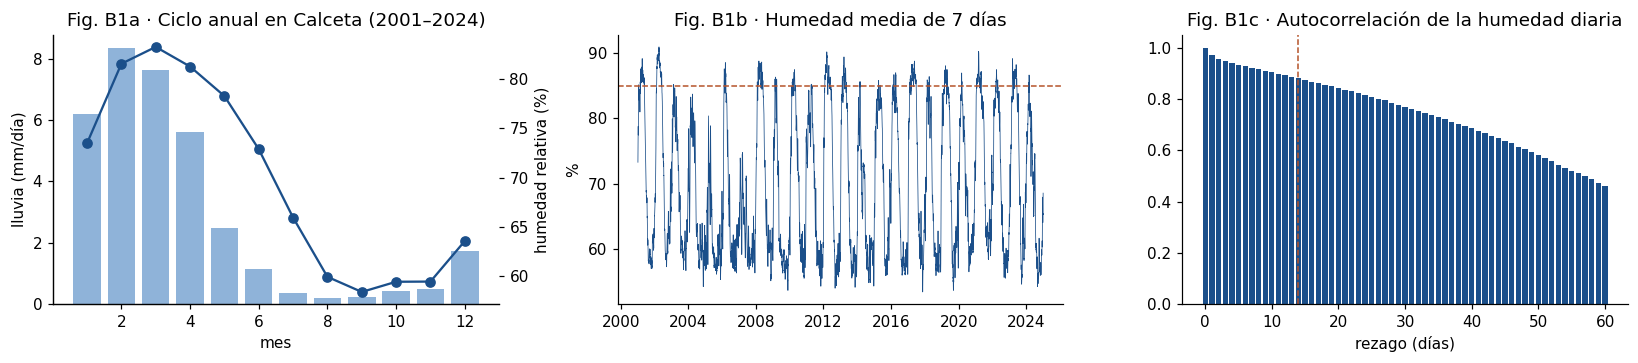

Humedad media por mes (%): {1: 73.5, 2: 81.5, 3: 83.2, 4: 81.2, 5: 78.3, 6: 72.9, 7: 66.0, 8: 60.0, 9: 58.4, 10: 59.5, 11: 59.5, 12: 63.6}
Autocorrelación de la humedad a 1, 7, 14 y 30 días: 0.97, 0.92, 0.88, 0.77
Días con lluvia > 0,1 mm: 70% · lluvia máxima: 153 mm


In [18]:
# Celda B2 · EDA: ciclo anual, años, lluvia y memoria de la humedad
# Grafica la humedad y la lluvia por mes, la serie completa y la autocorrelación de la humedad.

clima["mes"] = clima.fecha.dt.month
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
mens = clima.groupby("mes")[["RH2M", "PRECTOTCORR", "T2M"]].mean()
ax[0].bar(mens.index, mens.PRECTOTCORR, color="#8fb3d9", label="lluvia (mm/día)"); ax[0].set_xlabel("mes")
a2 = ax[0].twinx(); a2.plot(mens.index, mens.RH2M, "o-", color="#1b4f8a", label="humedad (%)"); a2.set_ylabel("humedad relativa (%)")
ax[0].set_title("Fig. B1a · Ciclo anual en Calceta (2001–2024)"); ax[0].set_ylabel("lluvia (mm/día)")
semanal = clima.set_index("fecha").RH2M.rolling(7).mean()
ax[1].plot(semanal.index, semanal, lw=0.5, color="#1b4f8a"); ax[1].axhline(85, color="#b5532a", ls="--", lw=1)
ax[1].set_title("Fig. B1b · Humedad media de 7 días"); ax[1].set_ylabel("%")
rh = clima.RH2M - clima.RH2M.mean()
acf = [1.0] + [float(np.corrcoef(rh[:-k], rh[k:])[0, 1]) for k in range(1, 61)]
ax[2].bar(range(61), acf, color="#1b4f8a", width=0.8); ax[2].axvline(14, color="#b5532a", ls="--", lw=1)
ax[2].set_title("Fig. B1c · Autocorrelación de la humedad diaria"); ax[2].set_xlabel("rezago (días)")
plt.tight_layout(); plt.show()
print("Humedad media por mes (%):", mens.RH2M.round(1).to_dict())
print(f"Autocorrelación de la humedad a 1, 7, 14 y 30 días: {acf[1]:.2f}, {acf[7]:.2f}, {acf[14]:.2f}, {acf[30]:.2f}")
print(f"Días con lluvia > 0,1 mm: {(clima.PRECTOTCORR > 0.1).mean():.0%} · lluvia máxima: {clima.PRECTOTCORR.max():.0f} mm")

### Decisiones que deja el EDA

| # | Hallazgo | Decisión |
|---|---|---|
| a | Ciclo anual fuerte: estación húmeda de enero a mayo (humedad media 78–83 %) y seca de julio a noviembre (58–60 %). | Se añaden **seno y coseno del día del año** como variables exógenas: la red sabe en qué época está sin tener que deducirlo. |
| b | La humedad tiene **memoria larga**: la autocorrelación sigue alta a 14 días y decae lentamente. | Ventana de referencia de **14 días** (la que propone la actividad): cubre la memoria reciente y el período de incubación corto de la roya. Una ventana larga (90 días) se usa en B6 para estudiar el desvanecimiento del gradiente. |
| c | La lluvia es muy asimétrica (muchos días en cero, picos de más de 100 mm). | Se transforma con **log(1 + x)** antes de normalizar. |
| d | La temperatura apenas varía (23–30 °C) y siempre está en el rango favorable a la roya. | El objetivo es la **humedad**, la variable que de verdad limita la infección en este sitio. |

## B3 · Ventanas, objetivo y partición por años

- **Entrada:** para cada día *t*, los 14 días *t − 13 … t* con 8 variables (las 6 de NASA POWER, con la lluvia en log, más seno y coseno del día del año), normalizadas con la media y la desviación **del entrenamiento**.
- **Objetivo:** la humedad relativa media de *t + 1 … t + 7* (la semana siguiente).
- **Partición que respeta el tiempo:** entrenamiento 2001–2016, validación 2017–2019 y prueba 2020–2024. Nunca se mezclan días: la red solo aprende del pasado. Se descartan las ventanas cuyo objetivo cruza el límite entre dos conjuntos (si no, la última semana de entrenamiento «vería» la primera de validación).

In [19]:
# Celda B3 · Ventanas de 14 días, objetivo a 7 días y partición por años
# Construye las variables, el objetivo y los índices de entrenamiento/validación/prueba sin cruzar fronteras.

VENTANA, HORIZONTE = 14, 7
ANIOS_B = {"entrenamiento": (2001, 2016), "validacion": (2017, 2019), "prueba": (2020, 2024)}
doy = clima.fecha.dt.dayofyear.to_numpy()
feat = clima[VARS_CLIMA].copy(); feat["PRECTOTCORR"] = np.log1p(feat.PRECTOTCORR)
feat["sen_dia"] = np.sin(2 * np.pi * doy / 365.25); feat["cos_dia"] = np.cos(2 * np.pi * doy / 365.25)
NOMBRES_B = list(feat.columns); XB = feat.to_numpy(np.float32)
RH = clima.RH2M.to_numpy()
y_semana = np.full(len(clima), np.nan)
for i in range(len(clima) - HORIZONTE): y_semana[i] = RH[i + 1: i + 1 + HORIZONTE].mean()
anio = clima.fecha.dt.year.to_numpy()

def conjunto_dia(i):
    if i < VENTANA - 1 or i + HORIZONTE >= len(clima): return None
    for nom, (a, b) in ANIOS_B.items():
        if a <= anio[i] <= b and a <= anio[i + HORIZONTE] <= b: return nom
    return None
conj_dia = np.array([conjunto_dia(i) for i in range(len(clima))], dtype=object)
IDX_B = {c: np.where(conj_dia == c)[0] for c in CONJ}
fin_entr = np.where(anio <= ANIOS_B["entrenamiento"][1])[0][-1] + 1
MU_B, SD_B = XB[:fin_entr].mean(0), XB[:fin_entr].std(0) + 1e-6
XBn = (XB - MU_B) / SD_B
YM_B, YS_B = y_semana[IDX_B["entrenamiento"]].mean(), y_semana[IDX_B["entrenamiento"]].std()

def ventanas(indices, w=VENTANA):
    return torch.tensor(np.stack([XBn[i - w + 1: i + 1] for i in indices]))
def objetivo(indices): return torch.tensor(((y_semana[indices] - YM_B) / YS_B).astype(np.float32))
DATOS_B = {c: (ventanas(IDX_B[c]).to(DEVICE), objetivo(IDX_B[c]).to(DEVICE)) for c in CONJ}
print(pd.DataFrame({"años": [f"{a}–{b}" for a, b in ANIOS_B.values()], "ventanas": [len(IDX_B[c]) for c in CONJ],
                    "humedad media objetivo (%)": [y_semana[IDX_B[c]].mean().round(1) for c in CONJ]}, index=CONJ).to_string())
print(f"Forma de la entrada: {tuple(DATOS_B['entrenamiento'][0].shape)} = (ventanas, días, variables)")

                    años  ventanas  humedad media objetivo (%)
entrenamiento  2001–2016      5824                        68.9
validacion     2017–2019      1088                        71.7
prueba         2020–2024      1820                        71.2
Forma de la entrada: (5824, 14, 8) = (ventanas, días, variables)


## B4 · Líneas base: ¿cuánto hay que superar?

Una red recurrente solo vale la pena si le gana a reglas simples:

- **Persistencia:** «la semana que viene será tan húmeda como la que pasó» (media de los últimos 7 días).
- **Climatología:** «será como el promedio histórico de esas fechas» (media 2001–2016 de cada día del año).
- **MLP aplanado:** el enfoque de la Fase 1. Las 14 × 8 cifras de la ventana se ponen en fila y entran a un perceptrón multicapa, que no sabe que los días tienen un orden.

Métricas, en puntos de humedad relativa: **RMSE** (castiga los errores grandes), **MAE** (error típico) y **MAPE** (error en % del valor real; se puede usar porque la humedad nunca es cero).

In [20]:
# Celda B4 · Métricas y líneas base (persistencia y climatología)
# Define RMSE/MAE/MAPE y calcula las dos reglas simples en validación y prueba.

def metricas_reg(pred, real):
    e = np.asarray(pred) - np.asarray(real)
    return {"RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(np.abs(e).mean()), "MAPE (%)": float(100 * np.abs(e / real).mean())}

clim_dia = pd.Series(RH[:fin_entr]).groupby(doy[:fin_entr]).mean()
def pred_climatologia(i): return np.mean([clim_dia[((doy[i] + k - 1) % 365) + 1] for k in range(1, HORIZONTE + 1)])
def pred_persistencia(i): return RH[i - HORIZONTE + 1: i + 1].mean()
filas_b = []
for nom, f in [("Persistencia", pred_persistencia), ("Climatología 2001–2016", pred_climatologia)]:
    for c in ["validacion", "prueba"]:
        filas_b.append({"modelo": nom, "conjunto": c, **metricas_reg([f(i) for i in IDX_B[c]], y_semana[IDX_B[c]])})
pd.DataFrame(filas_b).set_index(["modelo", "conjunto"]).round(3)

RMSE    MAE  MAPE (%)
modelo                 conjunto                          
Persistencia           validacion  3.087  2.268     3.266
                       prueba      2.741  2.104     3.007
Climatología 2001–2016 validacion  5.628  4.450     5.965
                       prueba      4.999  3.788     5.143

## B5 · Tres celdas recurrentes (y el MLP de contraste)

Las tres redes tienen la **misma forma**: una capa recurrente de **64 unidades** que recorre los 14 días, y una capa lineal que convierte su último estado oculto en el pronóstico. Ese último estado es el *embedding* `z_seq` que usará la fusión.

- **RNN simple** (contraste): $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. Sin compuertas: el gradiente que vuelve hacia los días viejos se multiplica una y otra vez por $W_h$ y tiende a desvanecerse.
- **LSTM**: añade un **estado de celda** y tres compuertas (olvido, entrada, salida) que deciden qué recordar. 4 bloques de pesos.
- **GRU**: dos compuertas (actualización y reinicio) y un solo estado. 3 bloques de pesos: unos 25 % menos parámetros que la LSTM.

Hiperparámetros comunes (los que sugiere la actividad): Adam con tasa **0,001**, lotes de **32**, pérdida MSE, hasta 80 épocas con **parada temprana** (paciencia 10, sobre la pérdida de validación). Cada red se entrena con **3 semillas** para separar las diferencias reales del azar de la inicialización.

In [21]:
# Celda B5 · Entrenamiento de MLP, RNN, LSTM y GRU con 3 semillas
# Entrena las cuatro redes con los mismos datos e hiperparámetros, guarda el historial y el mejor estado.

class RedSecuencia(nn.Module):
    def __init__(self, tipo, n_var=len(NOMBRES_B), oculto=64, w=VENTANA):
        super().__init__(); self.tipo = tipo
        if tipo == "MLP": self.rec = nn.Sequential(nn.Flatten(), nn.Linear(n_var * w, oculto), nn.ReLU())
        else: self.rec = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[tipo](n_var, oculto, batch_first=True)
        self.salida = nn.Linear(oculto, 1)
    def embedding(self, x):                        # z_seq: último estado oculto (64 números)
        if self.tipo == "MLP": return self.rec(x)
        h, _ = self.rec(x); return h[:, -1]
    def forward(self, x): return self.salida(self.embedding(x)).squeeze(1)

def entrenar_secuencia(tipo, semilla, datos, w=VENTANA, epocas=80, paciencia=10, lote=32):
    fijar_semillas(semilla); red = RedSecuencia(tipo, w=w).to(DEVICE)
    opt = torch.optim.Adam(red.parameters(), lr=1e-3)
    Xtr, ytr = datos["entrenamiento"]; Xva, yva = datos["validacion"]
    mejor, estado, hist, sin_mejora = np.inf, None, [], 0
    for ep in range(epocas):
        red.train(); perm = torch.randperm(len(Xtr), device=DEVICE); tot = 0.0
        for j in range(0, len(Xtr), lote):
            b = perm[j:j + lote]; opt.zero_grad()
            perdida = F.mse_loss(red(Xtr[b]), ytr[b]); perdida.backward(); opt.step(); tot += perdida.item() * len(b)
        red.eval()
        with torch.no_grad(): pv = F.mse_loss(red(Xva), yva).item()
        hist.append((tot / len(Xtr), pv))
        if pv < mejor - 1e-5: mejor, estado, sin_mejora, ep_mejor = pv, copy.deepcopy(red.state_dict()), 0, ep + 1
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    red.load_state_dict(estado); red.eval()
    return red, {"hist": hist, "epoca_mejor": ep_mejor}

@torch.no_grad()
def pronostico(red, X): return red(X).cpu().numpy() * YS_B + YM_B

TIPOS_B, SEMILLAS_B = ["MLP", "RNN", "LSTM", "GRU"], [42, 7, 2026]
modelos_B, filas_sem = {}, []
t0 = time.time()
for tipo in TIPOS_B:
    for s in SEMILLAS_B:
        red, info = entrenar_secuencia(tipo, s, DATOS_B)
        modelos_B[(tipo, s)] = (red, info)
        m = metricas_reg(pronostico(red, DATOS_B["validacion"][0]), y_semana[IDX_B["validacion"]])
        filas_sem.append({"red": tipo, "semilla": s, "época del mínimo": info["epoca_mejor"], **m,
                          "parámetros": sum(p.numel() for p in red.parameters())})
    print(f"  {tipo}: listo ({time.time() - t0:.0f} s)")
por_semilla = pd.DataFrame(filas_sem)
resumen_B = por_semilla.groupby("red", sort=False).agg(**{"RMSE val (media)": ("RMSE", "mean"), "RMSE val (desv.)": ("RMSE", "std"),
                                                         "MAE val": ("MAE", "mean"), "MAPE val (%)": ("MAPE (%)", "mean"),
                                                         "época del mínimo": ("época del mínimo", "mean"), "parámetros": ("parámetros", "first")})
resumen_B.round(3)

  MLP: listo (22 s)
  RNN: listo (44 s)
  LSTM: listo (65 s)
  GRU: listo (92 s)


,RMSE val (media),RMSE val (desv.),MAE val,MAPE val (%),época del mínimo,parámetros
red,,,,,,
MLP,2.168,0.003,1.628,2.334,16.333,7297
RNN,2.218,0.035,1.653,2.366,8.000,4801
LSTM,2.189,0.023,1.632,2.334,5.333,19009
GRU,2.174,0.016,1.616,2.316,6.000,14273


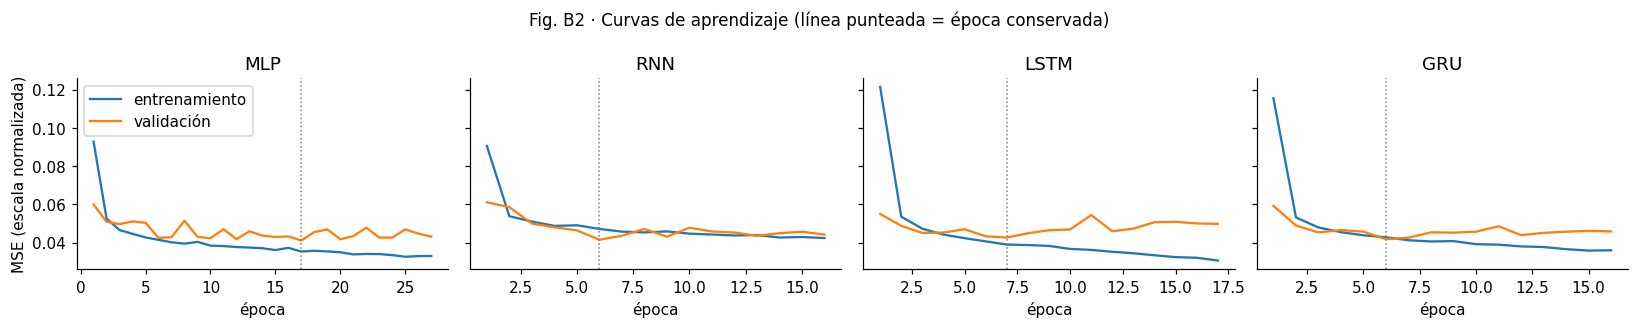

In [22]:
# Celda B5b · Curvas de aprendizaje (semilla 42)
# Muestra la pérdida de entrenamiento y de validación por época para cada red.

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, tipo in zip(axes, TIPOS_B):
    h = np.array(modelos_B[(tipo, 42)][1]["hist"])
    ax.plot(range(1, len(h) + 1), h[:, 0], label="entrenamiento"); ax.plot(range(1, len(h) + 1), h[:, 1], label="validación")
    ax.axvline(modelos_B[(tipo, 42)][1]["epoca_mejor"], color="gray", ls=":", lw=1)
    ax.set_title(tipo); ax.set_xlabel("época")
axes[0].set_ylabel("MSE (escala normalizada)"); axes[0].legend()
plt.suptitle("Fig. B2 · Curvas de aprendizaje (línea punteada = época conservada)", fontsize=11); plt.tight_layout(); plt.show()

## B6 · El desvanecimiento del gradiente, medido

Con 14 días, una RNN simple puede rendir parecido a una LSTM: la dependencia es corta. La diferencia aparece cuando la secuencia se alarga. Se entrenan las tres celdas con una ventana de 90 días (mismo objetivo) y, sobre un lote de validación, se mide cuánto gradiente llega a cada día de la ventana: $\lVert \partial L / \partial x_t \rVert$. Si el gradiente que llega al día 1 (hace 90 días) es casi cero, la red no puede aprender de lo que pasó entonces, aunque importe.

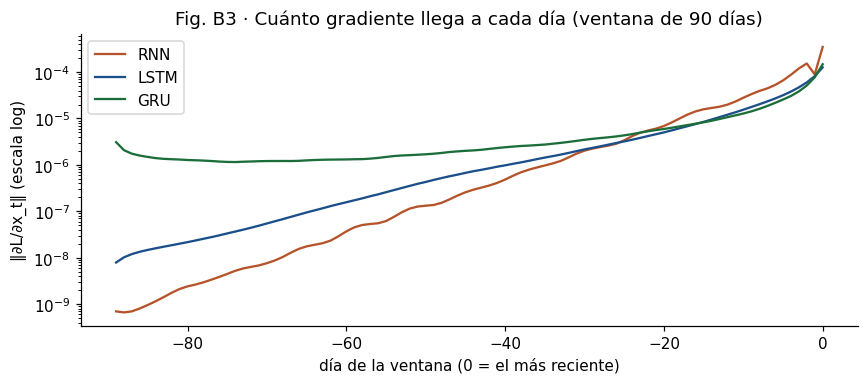

,RMSE val (90 días),"RMSE val (14 días, semilla 42)",gradiente al día más reciente,gradiente al día más antiguo,reciente / antiguo
red,,,,,
RNN,2.203,2.178,3.48e-04,6.96e-10,5.0e+05
LSTM,2.119,2.208,1.26e-04,7.87e-09,1.6e+04
GRU,2.126,2.185,1.47e-04,3.09e-06,4.8e+01


In [23]:
# Celda B6 · Normas del gradiente por paso con ventana de 90 días
# Reentrena RNN, LSTM y GRU con ventanas de 90 días y mide |∂L/∂x_t| en cada día de la ventana.

W_LARGA = 90
IDX_L = {c: IDX_B[c][IDX_B[c] >= W_LARGA - 1] for c in CONJ}
DATOS_L = {c: (ventanas(IDX_L[c], W_LARGA).to(DEVICE), objetivo(IDX_L[c]).to(DEVICE)) for c in CONJ}
perfiles, filas_l = {}, []
for tipo in ["RNN", "LSTM", "GRU"]:
    red, info = entrenar_secuencia(tipo, 42, DATOS_L, w=W_LARGA, epocas=30 if not MODO_PRUEBA else 2)
    m = metricas_reg(pronostico(red, DATOS_L["validacion"][0]), y_semana[IDX_L["validacion"]])
    red.train()                                        # cuDNN solo calcula gradientes de RNN en modo entrenamiento
    xb = DATOS_L["validacion"][0][:256].clone().requires_grad_(True)
    F.mse_loss(red(xb), DATOS_L["validacion"][1][:256]).backward()
    perfiles[tipo] = xb.grad.norm(dim=2).mean(0).cpu().numpy()      # una norma por día de la ventana
    red.eval()
    filas_l.append({"red": tipo, "RMSE val (90 días)": m["RMSE"],
                    "RMSE val (14 días, semilla 42)": por_semilla.query("red == @tipo and semilla == 42").RMSE.item(),
                    "gradiente al día más reciente": perfiles[tipo][-1], "gradiente al día más antiguo": perfiles[tipo][0],
                    "reciente / antiguo": perfiles[tipo][-1] / perfiles[tipo][0]})
fig, ax = plt.subplots(figsize=(8, 3.6))
for tipo, col in zip(["RNN", "LSTM", "GRU"], ["#b5532a", "#1b4f8a", "#1b6e3a"]):
    ax.semilogy(np.arange(-W_LARGA + 1, 1), perfiles[tipo], color=col, label=tipo)
ax.set_xlabel("día de la ventana (0 = el más reciente)"); ax.set_ylabel("‖∂L/∂x_t‖ (escala log)")
ax.set_title("Fig. B3 · Cuánto gradiente llega a cada día (ventana de 90 días)"); ax.legend(); plt.tight_layout(); plt.show()
tabla_grad = pd.DataFrame(filas_l).set_index("red")
tabla_grad.style.format({"RMSE val (90 días)": "{:.3f}", "RMSE val (14 días, semilla 42)": "{:.3f}",
                         "gradiente al día más reciente": "{:.2e}", "gradiente al día más antiguo": "{:.2e}", "reciente / antiguo": "{:.1e}"})

## B7 · Elección de la celda y evaluación única en prueba

Se elige por el **RMSE medio de validación** de las 3 semillas. Si LSTM y GRU quedan a menos de una desviación estándar, se prefiere la **GRU** por tener menos parámetros (más rápida, menos riesgo de sobreajuste). De la celda elegida se usa la semilla con mejor validación. La prueba (2020–2024) se mira **una sola vez**, para todos los modelos a la vez.

Celda elegida: GRU (semilla 2026) · empate dentro del ruido entre semillas → la más liviana


,RMSE,MAE,MAPE (%),RMSE desv. (3 semillas),mejora del RMSE vs persistencia (%)
modelo,,,,,
Persistencia,2.741,2.104,3.007,NaN,0.000
Climatología 2001–2016,4.999,3.788,5.143,NaN,-82.346
MLP,2.359,1.834,2.618,0.016,13.932
RNN,2.257,1.744,2.492,0.035,17.675
LSTM,2.305,1.783,2.535,0.039,15.929
GRU,2.205,1.715,2.446,0.017,19.575


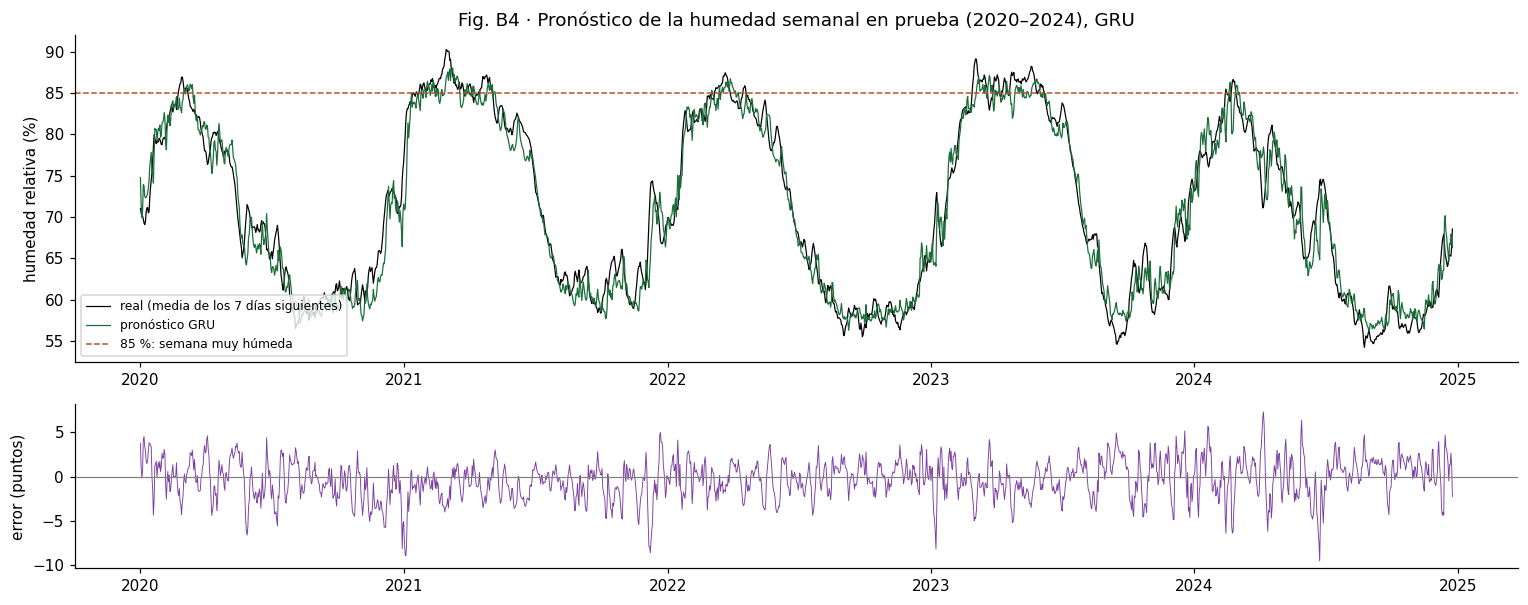

In [24]:
# Celda B7 · Elección LSTM vs GRU en validación y evaluación única en prueba
# Aplica la regla de elección, evalúa todos los modelos en 2020–2024 y grafica pronóstico frente a real.

r_lstm, r_gru = resumen_B.loc["LSTM"], resumen_B.loc["GRU"]
empate = abs(r_lstm["RMSE val (media)"] - r_gru["RMSE val (media)"]) < max(r_lstm["RMSE val (desv.)"], r_gru["RMSE val (desv.)"])
CELDA_B = "GRU" if (empate or r_gru["RMSE val (media)"] < r_lstm["RMSE val (media)"]) else "LSTM"
SEM_B = int(por_semilla[por_semilla.red == CELDA_B].sort_values("RMSE").semilla.iloc[0])
modelo_B = modelos_B[(CELDA_B, SEM_B)][0]
print(f"Celda elegida: {CELDA_B} (semilla {SEM_B}) · {'empate dentro del ruido entre semillas → la más liviana' if empate else 'mejor RMSE medio de validación'}")

Xte_B = DATOS_B["prueba"][0]; y_te_B = y_semana[IDX_B["prueba"]]
filas_te = [{"modelo": nom, **metricas_reg([f(i) for i in IDX_B["prueba"]], y_te_B)}
            for nom, f in [("Persistencia", pred_persistencia), ("Climatología 2001–2016", pred_climatologia)]]
for tipo in TIPOS_B:
    for s in SEMILLAS_B:
        filas_te.append({"modelo": tipo, "semilla": s, **metricas_reg(pronostico(modelos_B[(tipo, s)][0], Xte_B), y_te_B)})
te_B = pd.DataFrame(filas_te)
prueba_B = te_B.groupby("modelo", sort=False)[["RMSE", "MAE", "MAPE (%)"]].mean()
prueba_B["RMSE desv. (3 semillas)"] = te_B.groupby("modelo", sort=False).RMSE.std()
prueba_B["mejora del RMSE vs persistencia (%)"] = 100 * (1 - prueba_B.RMSE / prueba_B.loc["Persistencia", "RMSE"])
display(prueba_B.round(3))

pred_te_B = pronostico(modelo_B, Xte_B); fechas_te = clima.fecha.to_numpy()[IDX_B["prueba"]]
fig, ax = plt.subplots(2, 1, figsize=(14, 5.6), gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(fechas_te, y_te_B, color="black", lw=0.8, label="real (media de los 7 días siguientes)")
ax[0].plot(fechas_te, pred_te_B, color="#1b6e3a", lw=0.8, label=f"pronóstico {CELDA_B}")
ax[0].axhline(85, color="#b5532a", ls="--", lw=1, label="85 %: semana muy húmeda")
ax[0].set_ylabel("humedad relativa (%)"); ax[0].legend(loc="lower left", fontsize=8); ax[0].set_title(f"Fig. B4 · Pronóstico de la humedad semanal en prueba (2020–2024), {CELDA_B}")
ax[1].plot(fechas_te, pred_te_B - y_te_B, color="#7b3fa0", lw=0.6); ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_ylabel("error (puntos)"); plt.tight_layout(); plt.show()
torch.save(modelo_B.state_dict(), os.path.join(PESOS, f"serie_{CELDA_B.lower()}_w{VENTANA}.pth"))
json.dump({"celda": CELDA_B, "semilla": SEM_B, "ventana": VENTANA, "horizonte": HORIZONTE, "variables": NOMBRES_B,
           "media": MU_B.tolist(), "desv": SD_B.tolist(), "y_media": float(YM_B), "y_desv": float(YS_B)},
          open(os.path.join(PESOS, f"serie_{CELDA_B.lower()}_w{VENTANA}.json"), "w"), indent=1)

**Lectura de la rama B.**

- **Las redes le ganan a las reglas simples, con margen moderado.** En prueba (2020–2024), la GRU se equivoca en promedio 1,7 puntos de humedad (RMSE 2,21; MAPE 2,4 %), frente a 2,74 de la persistencia: un 19,6 % menos de error. La climatología queda muy atrás (RMSE 5,0): los años recientes no se parecen al promedio de 2001–2016, y repetir el calendario no sirve.
- **Entre arquitecturas, las diferencias son pequeñas.** En validación, las cuatro redes quedan entre 2,17 y 2,22 de RMSE, y el mejor promedio es incluso el del MLP aplanado de la Fase 1 (2,168). LSTM y GRU empatan dentro de la variación entre semillas (2,189 ± 0,023 frente a 2,174 ± 0,016). Con 14 días la dependencia es corta: la humedad de mañana se parece mucho a la de hoy (autocorrelación 0,97). La diferencia aparece al generalizar a años nuevos: en prueba, la GRU (2,21) supera a la RNN (2,26), la LSTM (2,31) y el MLP (2,36), con poca variación entre semillas.
- **El desvanecimiento del gradiente, medido (Fig. B3).** Con ventana de 90 días, el gradiente que llega al día más antiguo es 500.000 veces menor que el que llega al más reciente en la RNN simple; en la LSTM, 16.000 veces, y en la GRU, solo 48 veces. La RNN prácticamente no puede aprender de lo que pasó hace tres meses; las compuertas mantienen abierto ese camino. Con la ventana larga, LSTM y GRU mejoran (RMSE de validación 2,12 y 2,13, frente a 2,21 y 2,19 con 14 días) y la RNN no (2,20 frente a 2,18): solo las celdas con compuertas aprovechan la memoria larga. La mejora es pequeña porque, para este objetivo, casi toda la información útil está en los días recientes.
- **Elección: GRU (14 días).** Empata con la LSTM en validación, tiene 25 % menos parámetros (14.273 frente a 19.009) y es la que mejor generaliza en prueba. Su error típico (≈ 2,2 puntos) es pequeño frente al umbral de 85 % que usa la rama C: distingue con claridad una semana muy húmeda de una seca (Fig. B4), aunque falla en los cambios bruscos de estación. La ventana de 90 días daría un poco menos de error, pero la de 14 es la del diseño y se dejó fija antes de ver la prueba.
- **Reproducibilidad.** Las capas recurrentes en GPU (cuDNN) no son del todo deterministas: entre dos corridas completas, los RMSE variaron hasta 0,03, dentro de la desviación entre semillas. Por eso las conclusiones se apoyan en promedios de 3 semillas y no en una sola corrida.

---
# Rama C · Fusión de la hoja y el clima

La fusión tardía concatena los dos *embeddings*, $z = [\,z_{img} \,\Vert\, z_{seq}\,]$, y una cabeza pequeña decide con los dos. Antes de fusionar hay que responder la pregunta que más pesa en la rúbrica: ¿qué une una foto con un tramo de clima?

**La clave real.** Cada foto original de RoCoLe guarda en su EXIF la fecha de toma. El sitio es uno solo (Calceta). La clave es entonces (Calceta, día de toma) y el clima de una foto es el de los 14 días anteriores a ese día: el mismo tramo que leería el técnico.

**Sus límites, medidos y no supuestos.**

1. El paquete VOC (de donde salen las imágenes) borra el EXIF. Las fechas se leen de los archivos originales en Mendeley, pero su API solo lista 1.000 de las 1.560 fotos. Quedan fechadas las secciones C1–C5 y C10–C12; las secciones C6–C9 no tienen fecha accesible.
2. Las fotos fechadas se tomaron en solo 5 días (9, 10 y 11 de abril, 1 y 2 de mayo de 2019). Hay, por tanto, 5 tramos de clima distintos para casi mil fotos. El clima casi no varía entre fotos: en la práctica es una alineación agregada.
3. Cada día de toma corresponde a unas secciones del lote (p. ej., C1 el 2 de mayo). El clima de la foto también identifica, sin querer, en qué parte del lote se tomó.

Por eso la rama C se hace en dos partes:

- **C1 · Fusión con la clave real** (foto ↔ clima de sus 14 días previos), con ablación. Es la prueba honesta de si el clima de esos días aporta algo a la pregunta «¿qué tiene esta hoja?».
- **C2 · Fusión para la decisión del técnico**: «¿qué hojas con roya hay que revisar esta semana?». La unidad es el par (hoja, semana) y la etiqueta combina la clase de la hoja con la humedad real de la semana siguiente. Es una etiqueta construida (*proxy*), y se declara así.

In [25]:
# Celda C0 · Fecha de toma (EXIF) de las fotos originales de Mendeley
# Lista las fotos del dataset y lee de cada una solo los primeros 32 KB, donde está la fecha EXIF.

RUTA_FECHAS = os.path.join(DATOS, "fechas_exif_rocole.csv")
CARPETA_FOTOS = "1ca51fea-39e6-483f-a3f4-7e54cf3b4fd8"
if not os.path.exists(RUTA_FECHAS):
    from concurrent.futures import ThreadPoolExecutor
    def leer_fecha(f):
        req = urllib.request.Request(f["content_details"]["download_url"], headers={**CABECERAS, "Range": "bytes=0-32767"})
        cab = urllib.request.urlopen(req, timeout=60).read(32768)
        m = re.search(rb"\d{4}:\d\d:\d\d \d\d:\d\d:\d\d", cab)
        return {"archivo": f["filename"], "sha256_mendeley": f["content_details"]["sha256_hash"], "fecha_hora": m.group().decode() if m else None}
    try:
        req = urllib.request.Request(f"{MENDELEY_API}/files?version=2&folder_id={CARPETA_FOTOS}", headers=CABECERAS)
        lista = json.load(urllib.request.urlopen(req, timeout=60))
        with ThreadPoolExecutor(16) as ex: fechas = pd.DataFrame(list(ex.map(leer_fecha, lista)))
        fechas.to_csv(RUTA_FECHAS, index=False)
    except Exception as e:
        raise RuntimeError(f"No se pudieron leer las fechas desde Mendeley ({e}). Suba 'fechas_exif_rocole.csv' "
                           f"(incluido en el repositorio) a {DATOS} y vuelva a ejecutar la celda.")
fechas = pd.read_csv(RUTA_FECHAS)
fechas["fecha"] = pd.to_datetime(fechas.fecha_hora, format="%Y:%m:%d %H:%M:%S").dt.normalize()
print(f"Fotos listadas por la API de Mendeley: {len(fechas)} de 1.560 · con fecha EXIF: {fechas.fecha.notna().sum()}")
tabla_c = tabla[["id", "archivo", "seccion", "planta", "clase", "y", "nivel", "conjunto"]].reset_index(drop=True).merge(
    fechas[["archivo", "fecha"]], on="archivo", how="left")
tabla_c["fila_z"] = np.arange(len(tabla_c))                      # misma fila que Z_IMG y P_IMG (rama A)
print(f"Fotos de la tabla depurada con fecha: {tabla_c.fecha.notna().sum()} de {len(tabla_c)}")
print("\nFotos fechadas por día de toma y clase:")
print(pd.crosstab(tabla_c.fecha.dt.date, tabla_c.clase).reindex(columns=CLASES).to_string())
print("\nSecciones fotografiadas cada día:")
print(tabla_c.dropna(subset=["fecha"]).groupby(tabla_c.fecha.dt.date).seccion.agg(lambda s: ", ".join(sorted(s.unique(), key=lambda x: int(x[1:])))).to_string())

Fotos listadas por la API de Mendeley: 1000 de 1.560 · con fecha EXIF: 1000
Fotos de la tabla depurada con fecha: 922 de 1481

Fotos fechadas por día de toma y clase:
clase       sana  acaro  roya
fecha                        
2019-04-09     1      0     1
2019-04-10    76     20    53
2019-04-11   279     95   169
2019-05-01    46      7    31
2019-05-02    67      1    76

Secciones fotografiadas cada día:
fecha
2019-04-09                          C12
2019-04-10                     C10, C11
2019-04-11    C2, C3, C4, C10, C11, C12
2019-05-01                           C5
2019-05-02                           C1


## C1 · Fusión con la clave real (foto ↔ clima de sus 14 días previos)

Para cada foto fechada se calcula $z_{seq}$: la red de la rama B lee los 14 días que terminan **el día anterior** a la toma y entrega su estado oculto. $z_{img}$ es el *embedding* de 2.048 números de la CNN de la rama A. Se entrenan cuatro cabezas sobre la **misma etiqueta** (sana · ácaro · roya) y la **misma partición** de la rama A:

| Modelo | Entrada | Qué pregunta responde |
|---|---|---|
| Solo imagen | $z_{img}$ | ¿Cuánto sabe la foto sola? |
| Solo clima | $z_{seq}$ | ¿El clima de esos días predice la clase de la hoja? |
| Fusión | $[z_{img} \Vert z_{seq}]$ | ¿El clima añade algo a la foto? |
| **Control: solo fecha** | día de toma (5 categorías) | ¿Lo que aprende «solo clima» es clima, o es la fecha? |

El control es la clave del análisis. Si «solo clima» rinde igual que «solo fecha», lo que aprende **no es el efecto del clima** sino a qué días (y por tanto a qué secciones) pertenece cada foto.

Las cabezas son iguales en las cuatro: cada entrada pasa por una capa de 32 neuronas con *Dropout*; se concatenan y una capa lineal da las 3 clases. Pérdida ponderada por clase, parada temprana en validación y **5 semillas**.

In [26]:
# Celda C1 · Ablación con la clave real: solo imagen, solo clima, fusión y control «solo fecha»
# Calcula z_seq para el día de toma de cada foto y entrena las cuatro cabezas con 5 semillas.

idx_fecha = {f: np.where(clima.fecha.to_numpy() == np.datetime64(f - pd.Timedelta(days=1)))[0][0] for f in tabla_c.fecha.dropna().unique()}
with torch.no_grad():
    ZSEQ_DIA = {f: modelo_B.embedding(ventanas([i]).to(DEVICE)).cpu().numpy()[0] for f, i in idx_fecha.items()}
    RH7_DIA = {f: float(pronostico(modelo_B, ventanas([i]).to(DEVICE))[0]) for f, i in idx_fecha.items()}
print("Pronóstico de humedad de la semana siguiente para cada día de toma:", {str(f.date()): round(v, 1) for f, v in RH7_DIA.items()})

c1 = tabla_c.dropna(subset=["fecha"]).reset_index(drop=True)
dias_toma = sorted(c1.fecha.unique())
ENTRADAS_C1 = {
    "Solo imagen": [Z_IMG[c1.fila_z]],
    "Solo clima": [np.stack([ZSEQ_DIA[f] for f in c1.fecha])],
    "Fusión (imagen + clima)": [Z_IMG[c1.fila_z], np.stack([ZSEQ_DIA[f] for f in c1.fecha])],
    "Control: solo fecha": [np.eye(len(dias_toma), dtype=np.float32)[[dias_toma.index(f) for f in c1.fecha]]]}

class CabezaFusion(nn.Module):
    def __init__(self, dims, n_salida, p=0.3, interaccion=False):
        super().__init__()
        self.ramas = nn.ModuleList([nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Dropout(p)) for d in dims])
        if interaccion:    # capa oculta DESPUÉS de concatenar: permite combinar las ramas (p. ej., un «Y» lógico)
            self.salida = nn.Sequential(nn.Linear(32 * len(dims), 32), nn.ReLU(), nn.Dropout(p), nn.Linear(32, n_salida))
        else:              # salida lineal: el logit es una SUMA de lo que aporta cada rama (fusión aditiva)
            self.salida = nn.Linear(32 * len(dims), n_salida)
    def forward(self, *xs): return self.salida(torch.cat([r(x) for r, x in zip(self.ramas, xs)], 1))

def preparar(bloques, mascara_entr):           # estandariza cada bloque con la media y desviación del entrenamiento
    out = []
    for B_ in bloques:
        mu, sd = B_[mascara_entr].mean(0), B_[mascara_entr].std(0) + 1e-6
        out.append(torch.tensor(((B_ - mu) / sd).astype(np.float32), device=DEVICE))
    return out

def entrenar_cabeza_fusion(bloques, y, conj, n_salida, semilla, peso=None, epocas=400, paciencia=40, binaria=False, interaccion=False):
    fijar_semillas(semilla)
    m_tr, m_va = conj == "entrenamiento", conj == "validacion"
    Xs = preparar(bloques, m_tr); yt = torch.tensor(y, device=DEVICE)
    red = CabezaFusion([x.shape[1] for x in Xs], n_salida, interaccion=interaccion).to(DEVICE)
    opt = torch.optim.Adam(red.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.BCEWithLogitsLoss() if binaria else nn.CrossEntropyLoss(weight=peso)
    tr, va = torch.tensor(np.where(m_tr)[0], device=DEVICE), torch.tensor(np.where(m_va)[0], device=DEVICE)
    mejor, estado, sin_mejora = np.inf, None, 0
    for ep in range(epocas):
        red.train(); opt.zero_grad()
        sal = red(*[x[tr] for x in Xs]); perdida = crit(sal.squeeze(1), yt[tr].float()) if binaria else crit(sal, yt[tr])
        perdida.backward(); opt.step(); red.eval()
        with torch.no_grad():
            sv = red(*[x[va] for x in Xs]); pv = (crit(sv.squeeze(1), yt[va].float()) if binaria else crit(sv, yt[va])).item()
        if pv < mejor - 1e-5: mejor, estado, sin_mejora = pv, copy.deepcopy(red.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    red.load_state_dict(estado); red.eval()
    with torch.no_grad(): sal = red(*Xs)
    return red, (torch.sigmoid(sal.squeeze(1)) if binaria else F.softmax(sal, 1)).cpu().numpy()

y_c1, conj_c1 = c1.y.to_numpy(), c1.conjunto.to_numpy()
cta = np.bincount(y_c1[conj_c1 == "entrenamiento"], minlength=3)
peso_c1 = torch.tensor(len(y_c1[conj_c1 == "entrenamiento"]) / (3 * np.maximum(cta, 1)), dtype=torch.float32, device=DEVICE)
SEMILLAS_C = [42, 7, 2026, 11, 3] if not MODO_PRUEBA else [42]
filas_c1 = []
for nom, bloques in ENTRADAS_C1.items():
    for s in SEMILLAS_C:
        _, prob = entrenar_cabeza_fusion(bloques, y_c1, conj_c1, 3, s, peso=peso_c1)
        for c in ["validacion", "prueba"]:
            mk = conj_c1 == c; pr = prob[mk].argmax(1)
            f1c = f1_score(y_c1[mk], pr, labels=[0, 1, 2], average=None, zero_division=0)
            filas_c1.append({"modelo": nom, "semilla": s, "conjunto": c, "F1 macro": f1_score(y_c1[mk], pr, average="macro", zero_division=0),
                             "exactitud": accuracy_score(y_c1[mk], pr), "F1 sana": f1c[0], "F1 ácaro": f1c[1], "F1 roya": f1c[2]})
abl_c1 = pd.DataFrame(filas_c1)
print(f"Fotos fechadas: entrenamiento {sum(conj_c1 == 'entrenamiento')}, validación {sum(conj_c1 == 'validacion')}, prueba {sum(conj_c1 == 'prueba')}")
print(f"Referencia del azar (clase mayoritaria) en prueba: exactitud {np.mean(y_c1[conj_c1 == 'prueba'] == 0):.3f}, F1 macro {f1_score(y_c1[conj_c1 == 'prueba'], np.zeros(sum(conj_c1 == 'prueba'), int), average='macro', zero_division=0):.3f}")
resumen_c1 = abl_c1.groupby(["conjunto", "modelo"], sort=False)[["F1 macro", "exactitud", "F1 sana", "F1 ácaro", "F1 roya"]].mean()
resumen_c1["F1 macro desv."] = abl_c1.groupby(["conjunto", "modelo"], sort=False)["F1 macro"].std()
resumen_c1.round(3)

Pronóstico de humedad de la semana siguiente para cada día de toma: {'2019-04-11': 83.9, '2019-05-01': 85.3, '2019-04-10': 85.0, '2019-05-02': 85.6, '2019-04-09': 85.5}
Fotos fechadas: entrenamiento 640, validación 145, prueba 137
Referencia del azar (clase mayoritaria) en prueba: exactitud 0.496, F1 macro 0.221


,,F1 macro,exactitud,F1 sana,F1 ácaro,F1 roya,F1 macro desv.
conjunto,modelo,,,,,,
validacion,Solo imagen,0.741,0.834,0.908,0.496,0.820,0.031
prueba,Solo imagen,0.811,0.864,0.938,0.621,0.874,0.023
validacion,Solo clima,0.230,0.240,0.114,0.198,0.379,0.029
prueba,Solo clima,0.339,0.361,0.122,0.392,0.503,0.027
validacion,Fusión (imagen + clima),0.763,0.847,0.911,0.544,0.834,0.011
prueba,Fusión (imagen + clima),0.789,0.848,0.930,0.584,0.853,0.029
validacion,Control: solo fecha,0.255,0.306,0.347,0.159,0.259,0.018
prueba,Control: solo fecha,0.332,0.391,0.302,0.316,0.378,0.058


**Lectura de C1: con la clave real, el clima no aporta (y eso es un hallazgo).**

| Prueba (137 fotos fechadas, 5 semillas) | F1 macro | Exactitud |
|---|---|---|
| Solo imagen | **0,811** ± 0,023 | 0,864 |
| Fusión (imagen + clima) | 0,789 ± 0,029 | 0,848 |
| Solo clima | 0,339 | 0,361 |
| Control: solo fecha | 0,332 | 0,391 |
| Azar (clase mayoritaria) | 0,221 | 0,496 |

- **La fusión no supera a la imagen sola.** En validación sube 0,02 (0,763 frente a 0,741) y en prueba baja 0,02 (0,789 frente a 0,811): diferencias dentro de la variación entre semillas. El clima de los 14 días previos **no ayuda a saber qué tiene una hoja**.
- **«Solo clima» se comporta como «solo fecha».** Su F1 en prueba (0,339) es prácticamente igual al del control que solo conoce el día de toma (0,332), y en validación ambos quedan cerca o por debajo del azar (0,230 y 0,255). Con 5 días de toma, el clima solo toma 5 valores (su pronóstico de humedad va de 83,9 a 85,6 %): no mide un efecto del clima sobre la hoja, sino **qué día (y qué secciones del lote) se fotografió**. Por ejemplo, el 2 de mayo se fotografió la sección C1, que casi no tiene ácaro (1 de 144 fotos). Eso no es biología, es el calendario del muestreo, y no se repite entre conjuntos.
- **Por qué es el resultado esperado.** La roya tarda semanas en mostrar lesiones; la hoja de la foto refleja el clima de **meses** atrás y de toda la zona, no el de los 14 días previos a la foto. Con un solo sitio y 5 días de toma, ninguna arquitectura puede extraer una relación clima–hoja que los datos no contienen.

**Qué haría falta para que la fusión por muestra aportara:** fotos de **varios lotes** con clima distinto, o del **mismo lote a lo largo de varios meses** (seguimiento), para que el clima varíe entre muestras. Es la recomendación de datos para la Fase 3.

## C2 · Fusión para la decisión del técnico: ¿qué hojas revisar esta semana?

C1 responde una pregunta de laboratorio («¿qué tiene esta hoja?»). El técnico necesita otra: **«de las hojas que vi, ¿cuáles debo priorizar esta semana?»**. Una hoja con roya es más urgente si la semana que viene será **muy húmeda**, porque la humedad dispara nuevas infecciones a partir de esas lesiones. Una hoja con roya en semana seca puede esperar; una hoja sana no requiere visita aunque llueva.

**Unidad y clave de alineación.** El par **(hoja, semana)**: la hoja aporta su estado (rama A) y la semana aporta su pronóstico (rama B, desde el día anterior). Al par no se le inventa una fecha de foto: la pregunta es «si esta hoja estuviera así el lunes *d*, ¿sería prioridad?», que es lo que el técnico consulta cada semana.

**Etiqueta (*proxy* declarado).** $\text{prioridad}(h, d) = [\,\text{clase}(h) = \text{roya}\,] \wedge [\,\text{humedad media real de } d{+}1 \dots d{+}7 \ge 85\,\%\,]$. El 85 % separa el núcleo de la estación lluviosa en Calceta (Fig. B1b). **No es daño medido**: no existe un registro abierto de brotes por planta y semana. La etiqueta sirve para construir y evaluar la **mecánica** de la fusión y la disciplina de alineación, no para afirmar una predicción operativa de brotes.

**Anti-fuga por partida doble.** Un par va a entrenamiento solo si la hoja es de entrenamiento (partición de la rama A) **y** la semana es de 2001–2016; a prueba solo si la hoja es de prueba **y** la semana es de 2020–2024. Ni la CNN ve sus hojas de prueba ni la GRU sus años de prueba.

**Muestreo.** Por cada par positivo (roya, semana húmeda) se toman negativos difíciles: (roya, semana seca) y (no roya, semana húmeda), que obligan a usar las dos ramas, y unos pocos fáciles (no roya, semana seca).

**Ablación.** Solo imagen, solo serie y dos fusiones aprendidas: la **aditiva** (concatenar y una salida lineal, la forma mínima de la Fig. 4 de la actividad) y la **con interacción** (una capa oculta después de concatenar). La diferencia importa: con salida lineal, el logit es una **suma** de lo que aporta cada rama, y una suma no puede expresar bien un «Y» lógico. Como línea base sin entrenamiento, la **regla multiplicativa** $P(\text{roya}) \times P(\text{semana húmeda})$, con la segunda probabilidad derivada del pronóstico de la rama B y su error de validación.

In [27]:
# Celda C2 · Pares (hoja, semana) con doble partición y ablación
# Arma los pares con su etiqueta proxy, entrena solo imagen / solo serie / fusión y los compara con la regla multiplicativa.

from scipy.stats import norm
UMBRAL_HUMEDA = 85.0
with torch.no_grad():
    ZSEQ_B = {c: modelo_B.embedding(DATOS_B[c][0]).cpu().numpy() for c in CONJ}
    RH7_B = {c: pronostico(modelo_B, DATOS_B[c][0]) for c in CONJ}
sigma_B = float(np.sqrt(np.mean((RH7_B["validacion"] - y_semana[IDX_B["validacion"]]) ** 2)))
N_POS = {"entrenamiento": 2000, "validacion": 600, "prueba": 600} if not MODO_PRUEBA else {c: 60 for c in CONJ}
ES_ROYA = (tabla_c.clase == "roya").to_numpy()

def pares(c, rng):
    hojas = np.where(tabla_c.conjunto.to_numpy() == c)[0]
    roya, no_roya = hojas[ES_ROYA[hojas]], hojas[~ES_ROYA[hojas]]
    humeda = y_semana[IDX_B[c]] >= UMBRAL_HUMEDA; dh, ds = np.where(humeda)[0], np.where(~humeda)[0]
    n = N_POS[c]; P_ = []
    for grupo_h, grupo_d, k, et in [(roya, dh, n, 1), (roya, ds, n // 2, 0), (no_roya, dh, n // 2, 0), (no_roya, ds, n // 4, 0)]:
        P_ += [(h, d, et) for h, d in zip(rng.choice(grupo_h, k), rng.choice(grupo_d, k))]
    return np.array(P_)
rng_c2 = np.random.default_rng(SEMILLA)
PARES = {c: pares(c, rng_c2) for c in CONJ}
for c in CONJ:
    print(f"{c:14s}: {len(PARES[c]):5d} pares · {PARES[c][:, 2].mean():.0%} prioridad · "
          f"{len(np.unique(PARES[c][:, 0]))} hojas distintas · {len(np.unique(PARES[c][:, 1]))} semanas distintas · "
          f"semanas húmedas en el conjunto: {(y_semana[IDX_B[c]] >= UMBRAL_HUMEDA).mean():.0%}")

todos = np.concatenate([PARES[c] for c in CONJ]); conj_p = np.concatenate([[c] * len(PARES[c]) for c in CONJ])
zs_todos = np.concatenate([ZSEQ_B[c][PARES[c][:, 1]] for c in CONJ])
rh_todos = np.concatenate([RH7_B[c][PARES[c][:, 1]] for c in CONJ])
zi_todos = Z_IMG[tabla_c.fila_z.to_numpy()[todos[:, 0]]]
y_p = todos[:, 2].astype(np.int64)
ENTRADAS_C2 = {"Solo imagen": ([zi_todos], False), "Solo serie": ([zs_todos], False),
               "Fusión aditiva (concatenar + salida lineal)": ([zi_todos, zs_todos], False),
               "Fusión con interacción (concatenar + capa oculta)": ([zi_todos, zs_todos], True)}
probs_c2, filas_c2, redes_c2 = {}, [], {}
mk, mkv = conj_p == "prueba", conj_p == "validacion"
for nom, (bloques, inter) in ENTRADAS_C2.items():
    for s in SEMILLAS_C:
        red_c2, prob = entrenar_cabeza_fusion(bloques, y_p, conj_p, 1, s, binaria=True, interaccion=inter)
        if s == SEMILLAS_C[0]: probs_c2[nom], redes_c2[nom] = prob, red_c2
        filas_c2.append({"modelo": nom, "semilla": s, "ROC-AUC val": roc_auc_score(y_p[mkv], prob[mkv]),
                         "ROC-AUC": roc_auc_score(y_p[mk], prob[mk]), "PR-AUC": average_precision_score(y_p[mk], prob[mk])})
p_roya_img = P_IMG[tabla_c.fila_z.to_numpy()[todos[:, 0]], CLASES.index("roya")]
regla = p_roya_img * norm.cdf((rh_todos - UMBRAL_HUMEDA) / sigma_B)
probs_c2["Regla P(roya) × P(semana húmeda)"] = regla
filas_c2.append({"modelo": "Regla P(roya) × P(semana húmeda)", "semilla": "—", "ROC-AUC val": roc_auc_score(y_p[mkv], regla[mkv]),
                 "ROC-AUC": roc_auc_score(y_p[mk], regla[mk]),
                 "PR-AUC": average_precision_score(y_p[mk], regla[mk])})
abl_c2 = pd.DataFrame(filas_c2)
resumen_c2 = abl_c2.groupby("modelo", sort=False)[["ROC-AUC val", "ROC-AUC", "PR-AUC"]].agg(["mean", "std"])
# La fusión que usa el boletín se elige en VALIDACIÓN entre las dos aprendidas
FUSION_C2 = max([n for n in ENTRADAS_C2 if n.startswith("Fusión")], key=lambda n: abl_c2[abl_c2.modelo == n]["ROC-AUC val"].mean())
modelo_C2 = redes_c2[FUSION_C2]
print(f"Fusión elegida en validación para el boletín: {FUSION_C2}")
print(f"\nError típico del pronóstico de humedad (validación): {sigma_B:.2f} puntos")
resumen_c2.round(3)

entrenamiento :  4500 pares · 44% prioridad · 973 hojas distintas · 1918 semanas distintas · semanas húmedas en el conjunto: 10%
validacion    :  1350 pares · 44% prioridad · 209 hojas distintas · 566 semanas distintas · semanas húmedas en el conjunto: 18%
prueba        :  1350 pares · 44% prioridad · 220 hojas distintas · 604 semanas distintas · semanas húmedas en el conjunto: 12%
Fusión elegida en validación para el boletín: Fusión con interacción (concatenar + capa oculta)

Error típico del pronóstico de humedad (validación): 2.16 puntos


ROC-AUC val        ROC-AUC  \
                                                         mean    std    mean   
modelo                                                                         
Solo imagen                                             0.753  0.003   0.720   
Solo serie                                              0.768  0.003   0.790   
Fusión aditiva (concatenar + salida lineal)             0.894  0.005   0.895   
Fusión con interacción (concatenar + capa oculta)       0.900  0.007   0.899   
Regla P(roya) × P(semana húmeda)                        0.939    NaN   0.955   

                                                         PR-AUC         
                                                     std   mean    std  
modelo                                                                  
Solo imagen                                        0.007  0.609  0.011  
Solo serie                                         0.003  0.657  0.003  
Fusión aditiva (concatenar + salida lineal)        0.005  0.856  0.014  
Fusión con interacción (concatenar + capa oculta)  0.007  0.865  0.016  
Regla P(roya) × P(semana húmeda)                     NaN  0.934    NaN

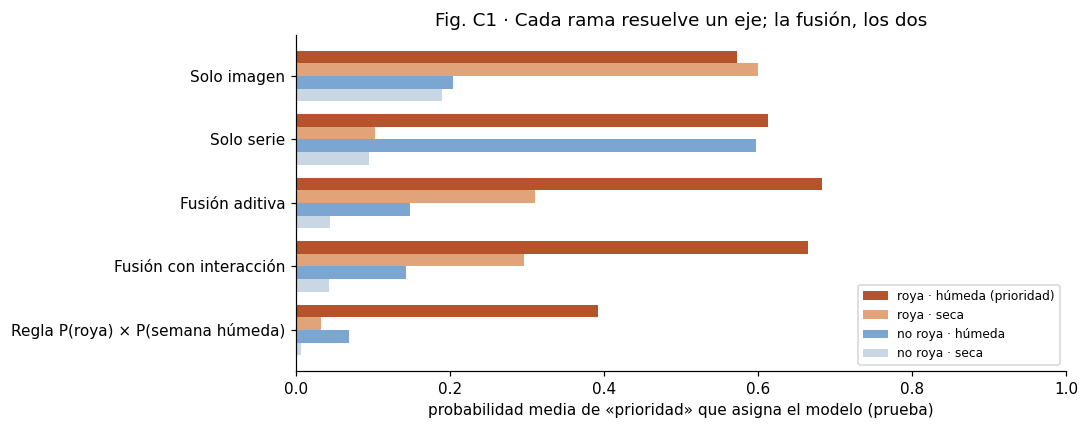

,Solo imagen,Solo serie,Fusión aditiva (concatenar + salida lineal),Fusión con interacción (concatenar + capa oculta),Regla P(roya) × P(semana húmeda)
roya · húmeda (prioridad),0.573,0.613,0.683,0.665,0.393
roya · seca,0.600,0.102,0.310,0.297,0.033
no roya · húmeda,0.204,0.598,0.148,0.143,0.068
no roya · seca,0.189,0.095,0.044,0.043,0.006


In [28]:
# Celda C2b · ¿Dónde acierta y dónde falla cada modelo? Puntaje por tipo de par (prueba)
# Promedia la probabilidad que asigna cada modelo a cada uno de los cuatro tipos de par.

tipo_par = np.select([ES_ROYA[todos[:, 0]] & (y_p == 1), ES_ROYA[todos[:, 0]] & (y_p == 0)], ["roya · húmeda (prioridad)", "roya · seca"], "")
hum_real = np.concatenate([y_semana[IDX_B[c]][PARES[c][:, 1]] >= UMBRAL_HUMEDA for c in CONJ])
tipo_par = np.where(tipo_par != "", tipo_par, np.where(hum_real, "no roya · húmeda", "no roya · seca"))
tab_tipo = pd.DataFrame({nom: pd.Series(p[mk]).groupby(tipo_par[mk]).mean() for nom, p in probs_c2.items()})
tab_tipo = tab_tipo.reindex(["roya · húmeda (prioridad)", "roya · seca", "no roya · húmeda", "no roya · seca"])
fig, ax = plt.subplots(figsize=(10, 4))
tab_tipo.T.plot.barh(ax=ax, color=["#b5532a", "#e0a37a", "#7aa6d1", "#c9d6e3"], width=0.8)
ax.set_yticks(range(len(tab_tipo.columns)), [n.split(" (")[0] for n in tab_tipo.columns])
ax.set_xlabel("probabilidad media de «prioridad» que asigna el modelo (prueba)"); ax.set_xlim(0, 1)
ax.set_title("Fig. C1 · Cada rama resuelve un eje; la fusión, los dos"); ax.legend(fontsize=8, loc="lower right"); ax.invert_yaxis()
plt.tight_layout(); plt.show()
tab_tipo.round(3)

**Lectura de C2.**

| Prueba (1.350 pares, 5 semillas) | ROC-AUC | PR-AUC |
|---|---|---|
| Solo imagen | 0,720 | 0,609 |
| Solo serie | 0,790 | 0,657 |
| Fusión aditiva | 0,895 ± 0,005 | 0,856 |
| Fusión con interacción (elegida en validación) | **0,899** ± 0,007 | 0,865 |
| Regla $P(\text{roya}) \times P(\text{semana húmeda})$, sin entrenar | **0,955** | **0,934** |

- **Cada rama sola ve un solo eje (Fig. C1).** La imagen sola da casi el mismo puntaje a una hoja con roya en semana húmeda (0,57) que en semana seca (0,60): no sabe qué semana viene. La serie sola da casi lo mismo a una semana húmeda con roya (0,61) que sin roya (0,60): no sabe qué tiene la hoja. Por eso ninguna pasa de 0,79 de AUC.
- **La fusión combina los dos ejes**: baja la prioridad de «roya en semana seca» a 0,30 y la de «sin roya en semana húmeda» a 0,14, y sube el AUC a 0,90. Es la ganancia que la ablación debía demostrar: **+0,11 sobre la mejor rama sola**.
- **La capa de interacción ayuda poco** (0,899 frente a 0,895, dentro del ruido), aunque en el boletín se nota: con ella, el orden de las plantas cambia entre la semana húmeda y la seca, y no solo sube o baja en bloque.
- **La regla sin entrenar le gana a toda fusión aprendida** (0,955). No es un fracaso del modelo, y conviene decirlo con claridad: la etiqueta se **construyó** con esa misma lógica («roya» Y «humedad ≥ 85 %»), y la regla usa directamente las dos salidas ya entrenadas (la probabilidad de roya de la CNN y el pronóstico de la GRU). La cabeza de fusión, en cambio, tiene que redescubrir el umbral de 85 % a partir de 2.048 + 64 números y 4.500 pares. **Cuando la regla de decisión ya se conoce, conviene escribirla, no aprenderla.** La fusión aprendida vale la pena cuando la combinación es desconocida y hay una etiqueta real (por ejemplo, brotes observados por planta y semana), que es lo que falta en datos abiertos.

**Lo que esto significa para el técnico (Fig. C2).** En una semana muy húmeda (marzo de 2021, 88 % pronosticado), **49 de las 57 plantas de prueba** superan 0,5 de prioridad y encabezan la lista las hojas con roya. En una semana seca (agosto de 2024, 56 %), **ninguna** pasa de 0,05. Un error visible: la planta C6P36, con ácaro, aparece entre las prioritarias de la semana húmeda porque la CNN confunde ácaro con roya (la frontera débil de la rama A). Para producción se recomienda la **regla multiplicativa**, que es más exacta y explicable, y guardar las visitas del técnico como etiquetas reales para entrenar la fusión en la Fase 3.

## C3 · Lo que vería el técnico

Una semana concreta del período de prueba, elegida por ser **muy húmeda** según el pronóstico. Con las hojas de prueba fotografiadas, el sistema ordena qué plantas revisar primero. Se muestra junto a una semana **seca** para comparar: las mismas hojas, otra prioridad.

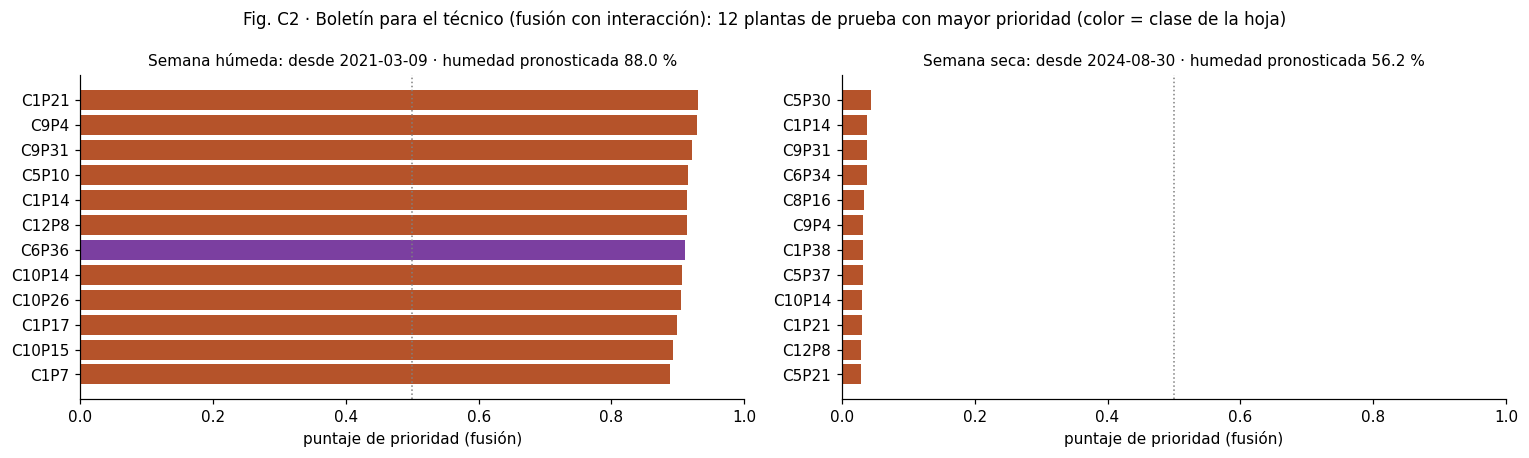

{'húmeda': {'fecha': '2021-03-09', 'humedad_pronosticada': 88.0075533842261, 'plantas_prioridad_>0,5': 49}, 'seca': {'fecha': '2024-08-30', 'humedad_pronosticada': 56.222689285249984, 'plantas_prioridad_>0,5': 0}}


In [29]:
# Celda C3 · Boletín semanal: plantas prioritarias en una semana húmeda y en una seca
# Aplica la fusión a todas las hojas de prueba en dos semanas reales de 2020–2024 y lista las plantas a revisar.

hojas_te = np.where(tabla_c.conjunto.to_numpy() == "prueba")[0]
rh_te = RH7_B["prueba"]; d_hum, d_seca = int(np.argmax(rh_te)), int(np.argmin(rh_te))
mk_tr = conj_p == "entrenamiento"
def puntaje_semana(d):
    bloques = [Z_IMG[tabla_c.fila_z.to_numpy()[hojas_te]], np.repeat(ZSEQ_B["prueba"][[d]], len(hojas_te), 0)]
    Xs = [torch.tensor(((B_ - ref[mk_tr].mean(0)) / (ref[mk_tr].std(0) + 1e-6)).astype(np.float32), device=DEVICE)
          for B_, ref in zip(bloques, ENTRADAS_C2[FUSION_C2][0])]
    with torch.no_grad(): return torch.sigmoid(modelo_C2(*Xs).squeeze(1)).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
boletin = {}
for ax, d, nom in [(axes[0], d_hum, "húmeda"), (axes[1], d_seca, "seca")]:
    pun = puntaje_semana(d)
    df_b = tabla_c.iloc[hojas_te][["planta", "archivo", "clase", "nivel"]].assign(puntaje=pun)
    por_planta = df_b.groupby("planta").agg(puntaje=("puntaje", "max"), clase=("clase", lambda c: "roya" if (c == "roya").any() else c.mode()[0]))
    top = por_planta.sort_values("puntaje", ascending=False).head(12)
    ax.barh(top.index[::-1], top.puntaje[::-1], color=[COLORES[c] for c in top.clase[::-1]])
    fecha_d = pd.Timestamp(clima.fecha.to_numpy()[IDX_B["prueba"][d]]).date()
    ax.set_title(f"Semana {nom}: desde {fecha_d} · humedad pronosticada {rh_te[d]:.1f} %", fontsize=10)
    ax.set_xlim(0, 1); ax.axvline(0.5, color="gray", ls=":", lw=1); ax.set_xlabel("puntaje de prioridad (fusión)")
    boletin[nom] = {"fecha": str(fecha_d), "humedad_pronosticada": float(rh_te[d]), "plantas_prioridad_>0,5": int((por_planta.puntaje > 0.5).sum())}
plt.suptitle(f"Fig. C2 · Boletín para el técnico ({FUSION_C2.split(' (')[0].lower()}): 12 plantas de prueba con mayor prioridad (color = clase de la hoja)", fontsize=11)
plt.tight_layout(); plt.show()
print(boletin)

In [30]:
# Celda C4 · Guardar pesos de la fusión y cifras de las ramas B y C
# Guarda el .pth de la cabeza de fusión y un JSON con todas las cifras que cita el informe.

torch.save(modelo_C2.state_dict(), os.path.join(PESOS, "fusion_prioridad_semana.pth"))
cifras_BC = {"huella_clima": huella_clima, "ventanas": {c: len(IDX_B[c]) for c in CONJ}, "celda_elegida": [CELDA_B, SEM_B],
             "validacion_B": resumen_B.reset_index().to_dict("records"), "prueba_B": prueba_B.reset_index().to_dict("records"),
             "gradiente_90": tabla_grad.reset_index().to_dict("records"),
             "fotos_fechadas": int(len(c1)), "dias_toma": [str(pd.Timestamp(f).date()) for f in dias_toma],
             "rh7_dias_toma": {str(f.date()): v for f, v in RH7_DIA.items()},
             "ablacion_C1": resumen_c1.reset_index().to_dict("records"),
             "ablacion_C2": abl_c2.groupby("modelo", sort=False)[["ROC-AUC val", "ROC-AUC", "PR-AUC"]].mean().reset_index().to_dict("records"), "fusion_boletin": FUSION_C2,
             "C2_por_tipo": tab_tipo.reset_index().to_dict("records"), "boletin": boletin, "sigma_B": sigma_B}
json.dump(limpio(cifras_BC), open(os.path.join(BASE, "cifras_ramas_BC.json"), "w"), ensure_ascii=False, indent=1)
print("Pesos guardados:", sorted(os.listdir(PESOS)))

Pesos guardados: ['cnn_resnet50_ft.json', 'cnn_resnet50_ft.pth', 'fusion_prioridad_semana.pth', 'serie_gru_w14.json', 'serie_gru_w14.pth']


---
# Conclusiones de la Fase 2

1. **La CNN supera con claridad al MLP de la Fase 1.** ResNet50 con *Fine-Tuning* clasifica sana · ácaro · roya con F1 macro 0,841 en prueba. Como alarma sana/enferma, iguala la meta de *recall* (0,92) con **5 falsas alarmas en vez de 38**, y mira la hoja (Grad-CAM: el doble de atención dentro de la hoja que el azar).
2. **La calidad de los datos pesó más que la arquitectura.** RoCoLe trae 67 fotos repetidas bajo nombres de otras plantas, 12 de ellas con etiquetas contradictorias. Depurarlas cerró una fuga entre conjuntos y quitó ruido justo en la frontera ácaro–roya.
3. **El clima es predecible a una semana, y las compuertas importan con memoria larga.** La GRU pronostica la humedad semanal con 2,2 puntos de error (19,6 % mejor que la persistencia). Con 90 días, la RNN simple pierde el gradiente (500.000 veces más débil en el día más antiguo) y no aprovecha la ventana larga; LSTM y GRU sí.
4. **Con la clave real (Calceta, fecha de la foto), el clima no aporta a la clase de la hoja**: solo identifica el día de muestreo. Es un resultado negativo honesto: los datos abiertos no contienen esa relación.
5. **Para la decisión semanal del técnico, combinar hoja y clima sí aporta** (AUC 0,90 frente a 0,79 de la mejor rama sola), pero con una etiqueta *proxy*, una regla multiplicativa explícita rinde más (0,955). Se recomienda usarla y recolectar visitas reales para entrenar la fusión en la Fase 3.